# How much information does a game review carry about its game? Robustness run: 100,000 reviews per game

This is a copy of `information_in_reviews.ipynb` with one change: `N_PER_GAME = 100_000` instead of 10,000, and outputs written to `results_100k/`. Everything else (eligibility rules, folds, models, checks) is identical. The narrative text in the markdown cells still quotes the numbers of the 10,000-per-game run; the cell outputs below are the 100,000-per-game numbers.

This notebook implements the information-theoretic analysis plan for the Steam review
dataset. The core idea: define the information content of a review as the amount by
which reading it reduces our uncertainty about **which game it is about**, then track
how that information varies with review length and calendar time.

Each review $i$ is a tuple $(R_i, X_i, Y_i, T_i, W_i)$:

- $R_i$ = review text
- $X_i$ = 384-dimensional embedding of the text (`bge-small-en-v1.5`)
- $Y_i$ = game ID (10 games)
- $T_i$ = timestamp
- $W_i$ = word count

The target quantity is

$$I(Y;X) = H(Y) - H(Y \mid X),$$

estimated through the held-out log-loss of a cross-fitted probabilistic classifier
(in bits). What is estimated is *usable* information about the game under this
representation and model family (predictive $\mathcal{V}$-information), a lower bound on
the Shannon mutual information of raw text.

The theory behind the estimator — what the bits estimate, why cross-fitting makes the
probe's estimation error second order, why the remaining $p/n$ bias term matters at this
sample size, and how the standard errors are justified — is written up separately in
`theory_note_rewritten.pdf`. This notebook contains the computations and, after each
result, a short note on what it shows.

Roadmap:

1. The corpus as a whole, and why the analysis runs on a balanced sample of it
2. Global information estimate
3. A per-review informativeness score $s_i$
4. Conditional version: what does the *text* add beyond timestamp + word count?
   4b. Confidence intervals for $I$ and tests of whether two models differ
5. Information by review length and by year
6. A longitudinal model
7. A decomposition: how much of the decline over time is just reviews getting shorter?
8. What the classifier actually predicts (heatmap and confusion matrix)
9. Per-game boxplots over time
10. Finite-sample checks behind the headline number: the bias of the cross-fitted
    estimate and the standard errors
11. Information and review characteristics: how the score relates to funny votes,
    positive/negative verdicts and helpfulness
12. Eligible reviews per game and year for the 100 most-reviewed games: which games
    meet the 10,000-per-game sampling condition


## 0. Setup

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import gc
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
import statsmodels.formula.api as smf

ROOT = Path("..").resolve()
DATA = ROOT / "data"
OUT = ROOT / "results_100k"
OUT.mkdir(exist_ok=True)

SEED = 42
N_FOLDS = 5
N_PER_GAME = 100_000    # robustness run: ten times the original balanced sample (see section 1)

GAME_FILES = [
    "game_reviews_218620.feather",  # PAYDAY 2
    "game_reviews_236390.feather",  # War Thunder
    "game_reviews_251570.feather",  # 7 Days to Die
    "game_reviews_284160.feather",  # BeamNG.drive
    "game_reviews_304930.feather",  # Unturned
    "game_reviews_377160.feather",  # Fallout 4
    "game_reviews_381210.feather",  # Dead by Daylight
    "game_reviews_413150.feather",  # Stardew Valley
    "game_reviews_438100.feather",  # VRChat
    "game_reviews_444090.feather",  # Paladins
]

## 1. The corpus, and why the analysis runs on a balanced sample

Before any modelling, this section describes the whole dataset — all ten games, all
languages, every review — because the shape of the corpus is what dictates the sampling
decision made at the end of the section.

The embedding matrix in `data/embeddings_v2.npz` was produced once, outside this notebook
(about 2.5 hours on CPU), by concatenating the ten feather files in a fixed order and encoding
every review — so row $i$ of the matrix is row $i$ of that concatenation. The script that did
it is kept as `_archive/full_pipeline.py`; the step that matters is

```python
model = SentenceTransformer("BAAI/bge-small-en-v1.5")
texts = reviews["review"].fillna("").values            # 4,623,482 strings, feather order
embeddings = model.encode(texts, batch_size=32, convert_to_numpy=True,
                          normalize_embeddings=False)   # -> (4623482, 384)
np.savez_compressed("data/embeddings_v2.npz", X=embeddings.astype(np.float32))
```

No matching metadata file survived that run (the script stopped after writing the matrix),
so this notebook rebuilds the metadata from the raw feather files in exactly the same order
and asserts that the row counts agree.

In [2]:
# read just the npz header (cheap) to learn the matrix shape before loading 6 GB
with zipfile.ZipFile(DATA / "embeddings_v2.npz") as z:
    with z.open("X.npy") as f:
        version = np.lib.format.read_magic(f)
        emb_shape, _, _ = np.lib.format._read_array_header(f, version)

# Walk the feather files in the order the embedding run used and tag every row with
# its position in that concatenation, so metadata and embeddings stay aligned.
cols = ["language", "review", "timestamp_created", "voted_up",
        "weighted_vote_score", "votes_up", "votes_funny", "appid"]
frames, offset = [], 0
for f in GAME_FILES:
    part = pd.read_feather(ROOT / "data" / "raw" / f, columns=cols)
    part["row"] = np.arange(offset, offset + len(part))
    offset += len(part)
    frames.append(part)

full = pd.concat(frames, ignore_index=True)
del frames
gc.collect()
assert len(full) == emb_shape[0], (len(full), emb_shape)

# appid is stored inconsistently across the feather files (string in some,
# integer in others) — coerce once here or every groupby/lookup breaks later
full["appid"] = pd.to_numeric(full["appid"]).astype(np.int64)
full["year"] = pd.to_datetime(full["timestamp_created"], unit="s").dt.year
# count runs of non-whitespace: same answer as len(text.split()), but without
# materialising millions of python lists
full["word_count"] = (full["review"].fillna("").astype(str)
                          .str.count(r"\S+").astype(int))

gi = pd.read_csv(ROOT / "data" / "game_info.csv")[["appid", "name"]].dropna(subset=["appid"])
NAMES = dict(zip(gi["appid"].astype(int), gi["name"]))
full["game_name"] = full["appid"].map(NAMES)

print(f"{len(full):,} reviews, embedding matrix {emb_shape} — aligned")

4,623,482 reviews, embedding matrix (4623482, 384) — aligned


### 1a. How big is the corpus, and how is it distributed?

In [3]:
corpus_matrix = (full.pivot_table(index="year", columns="game_name",
                                  values="appid", aggfunc="size")
                     .fillna(0).astype(int))
corpus_matrix["ALL"] = corpus_matrix.sum(axis=1)
corpus_matrix.loc["Total"] = corpus_matrix.sum(axis=0)
corpus_matrix.to_csv(OUT / "corpus_reviews_per_year_by_game.csv")
corpus_matrix

game_name,7 Days to Die,BeamNG.drive,Dead by Daylight,Fallout 4,PAYDAY 2,Paladins®,Stardew Valley,Unturned,VRChat,War Thunder,ALL
year,,,,,,,,,,,
2013,550,0,0,0,9379,0,0,0,0,5640,15569
2014,5733,225,0,0,57256,0,0,0,0,15712,78926
2015,5074,1986,0,36108,71713,0,0,25553,0,15936,156370
2016,8219,3324,46704,38410,60745,12987,41687,62788,0,16274,291138
2017,13764,4163,51387,40151,84922,71353,34127,53958,1596,16627,372048
2018,13429,4101,51676,22148,34126,40111,30537,26923,18683,17046,258780
2019,28321,11914,82343,28614,48786,43052,74561,38544,15212,29441,400788
2020,49099,27896,148025,47454,78079,55788,105709,66448,32045,55965,666508
2021,49713,46872,155174,42605,83489,35206,123339,57339,40101,69097,702935


Two things stand out, and together they decide the sampling design.

**The corpus is unbalanced across games.** The largest game has several times as many
reviews as the smallest. If I trained on the raw pool, the information estimate would
be dominated by whichever games happen to be popular, and "how identifiable is a
review" would get mixed up with "how common is its game."

**The corpus is unbalanced across years, and the game mix changes with the year.** Early
years contain only the two or three games that had launched by then; recent years
contain all ten. So the baseline uncertainty $H(Y)$ is itself different in every year.
Comparing information across years on the raw pool would compare numbers whose
denominators move — a year with three games starts from $\log_2 3 = 1.58$ bits of
uncertainty, a year with ten starts from $3.32$.

### 1b. The analysis sample

Given the above, the modelling sections use a **balanced sample: `N_PER_GAME` English
reviews drawn uniformly at random from each game**.

What balancing buys:

- $H(Y) = \log_2 10 = 3.32$ bits exactly, and the same value in every subset I compare,
  so $I_\text{norm}$ has one fixed denominator and the year-to-year and
  length-bucket-to-length-bucket numbers are on a common scale.
- No single game drives the estimate; the result reads as "how identifiable is a review
  for a typical one of these ten games."
- Sampling is uniform *within* each game, so each game's own composition over time and
  over review length is preserved — the longitudinal trends are not distorted.

What it costs, stated plainly: the information is measured against a uniform prior, not
against the real-world prior in which Stardew Valley reviews are three times as common
as Paladins reviews. The number answers "how much does the text tell you about which of
ten equally likely games this is," not "how much does it tell you about which game this
is, given the real popularity mix." Section 1a is the record of what that real mix looks
like.

Two further filters. **Reviews that name a game are removed.** A review that says
"best Fallout in the series" identifies its game by the name, not by anything about the
review; keeping such reviews would credit the text with information that is really a
label. The filter matches the ten games' names, franchise names and common abbreviations
(patterns listed in the code) anywhere in the review, case-insensitively, and removes the
review from the pool before sampling. The cell reports how many reviews this affects, per
game.

The other filter is language. `bge-small-en-v1.5` is an English-only encoder, so its
embeddings of Russian or Chinese text are not trustworthy, and language is itself a
strong proxy for game identity — including other languages would credit the review text
with information that really comes from the language tag.

In [4]:
# reviews that name one of the ten games (name, franchise name, or a common abbreviation)
NAME_PATTERNS = {
    "PAYDAY 2":         r"pay\s?day",
    "War Thunder":      r"war\s?thunder",
    "7 Days to Die":    r"7\s?days|seven days|7dtd|7d2d",
    "BeamNG.drive":     r"beam\s?ng",
    "Unturned":         r"unturned",
    "Fallout 4":        r"fallout|\bfo4\b",
    "Dead by Daylight": r"dead by daylight|\bdbd\b",
    "Stardew Valley":   r"stardew",
    "VRChat":           r"vr\s?chat",
    "Paladins":         r"\bpaladins\b",
}
text_lower = full["review"].fillna("").astype(str).str.lower()
eng = (full["language"] == "english").to_numpy()
full["names_game"] = False
name_counts = {}
for g, pat in NAME_PATTERNS.items():
    hit = text_lower.str.contains(pat, regex=True).to_numpy()
    name_counts[g] = int((hit & eng).sum())
    full["names_game"] |= hit
del text_lower
gc.collect()
n_named = int((full["names_game"].to_numpy() & eng).sum())
print(f"English reviews that name a game: {n_named:,} of {int(eng.sum()):,} ({n_named / eng.sum():.1%}), removed")
print(pd.Series(name_counts, name="English reviews matching the name").to_string())

pool = full[eng & (full["word_count"] >= 1) & ~full["names_game"]]
print(f"\neligible pool: {len(pool):,} English reviews with at least one word and no game name")

rng = np.random.default_rng(SEED)
picks = []
for g, sub in pool.groupby("appid"):
    take = min(N_PER_GAME, len(sub))
    picks.append(rng.choice(sub.index.values, size=take, replace=False))
sample_pos = np.sort(np.concatenate(picks))

df = full.loc[sample_pos].reset_index(drop=True)
idx = df.pop("row").to_numpy()          # positions into the embedding matrix
df["clean"] = df.pop("review").fillna("").astype(str).str.strip()
df["logW"] = np.log2(df["word_count"].astype(float))
y = df["appid"].to_numpy(dtype=np.int64)

# metadata for every review in the corpus (no text), used in section 11 to score them all
meta_all = full[["row", "appid", "game_name", "language", "year", "word_count", "voted_up",
                 "votes_up", "votes_funny", "weighted_vote_score", "names_game"]].copy()
meta_all["in_sample"] = False
meta_all.loc[sample_pos, "in_sample"] = True

del full, pool
gc.collect()

print(f"analysis sample: {len(df):,} reviews")

English reviews that name a game: 170,483 of 2,122,229 (8.0%), removed
PAYDAY 2            23401
War Thunder         11283
7 Days to Die        7426
BeamNG.drive         4589
Unturned             7992
Fallout 4           57332
Dead by Daylight    13738
Stardew Valley      26123
VRChat              12195
Paladins             6978

eligible pool: 1,943,921 English reviews with at least one word and no game name
analysis sample: 1,000,000 reviews


In [5]:
# load the embedding matrix and keep only the sampled rows
print("loading the ~6 GB embedding matrix, takes a minute...")
X_all = np.load(DATA / "embeddings_v2.npz")["X"]
X = X_all[idx].copy()
del X_all
gc.collect()
print("X:", X.shape, X.dtype)

loading the ~6 GB embedding matrix, takes a minute...
X: (1000000, 384) float32


## 2. Global information estimate

Train a probabilistic classifier $\hat p(Y \mid X)$ (multinomial logistic regression on
the embeddings) with **cross-fitting**: 5 stratified folds, each review scored by a
model that never saw it. That avoids optimistic information estimates.

$$\widehat H(Y \mid X) = \frac{1}{n}\sum_i -\log_2 \hat p_{-fold(i)}(Y_i \mid X_i)$$

$$\hat I_{\text{text}} = \widehat H(Y) - \widehat H(Y \mid X)
\qquad
\hat I_{\text{norm}} = 1 - \frac{\widehat H(Y \mid X)}{\widehat H(Y)}$$

$\hat I_{\text{norm}}$ is a clean "information index": 0 = the embedding tells us
nothing beyond the game distribution, 1 = perfect game identification.

The accuracy-based index, from the same held-out predictions:

$$I_{\text{acc}} = 1 - \frac{e_{\text{model}}}{e_{\text{base}}},\qquad e_{\text{base}} = 1 - \max_g p(g)$$

In [6]:
def crossfit_proba(F, y, n_folds=N_FOLDS, seed=SEED):
    # out-of-fold predicted probabilities
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    proba = np.zeros((len(y), np.unique(y).size), dtype=np.float32)
    for k, (tr, te) in enumerate(skf.split(F, y)):
        clf = LogisticRegression(max_iter=1000, n_jobs=-1)
        clf.fit(F[tr], y[tr])
        proba[te] = clf.predict_proba(F[te])
        print(f"  fold {k + 1}/{n_folds} done", flush=True)
    return proba

classes = np.unique(y)
cix = {g: i for i, g in enumerate(classes)}
truth = np.array([cix[g] for g in y])

print("cross-fitting p(Y | X) on embeddings...")
proba_x = crossfit_proba(X, y)
p_true_x = np.clip(proba_x[np.arange(len(y)), truth], 1e-12, 1)

cross-fitting p(Y | X) on embeddings...
  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done


In [7]:
prior = df["appid"].value_counts(normalize=True).reindex(classes).to_numpy()
H_Y = float(-(prior * np.log2(prior)).sum())
H_YgX = float((-np.log2(p_true_x)).mean())
I_text = H_Y - H_YgX
I_norm = 1 - H_YgX / H_Y

acc = float((proba_x.argmax(1) == truth).mean())
e_model, e_base = 1 - acc, 1 - prior.max()
I_acc = 1 - e_model / e_base

glob = pd.DataFrame({
    "quantity": ["H(Y)", "H(Y|X)", "I_text = H(Y)-H(Y|X)", "I_norm",
                 "accuracy", "error e_model", "baseline error e_base", "I_acc"],
    "bits_or_rate": [H_Y, H_YgX, I_text, I_norm, acc, e_model, e_base, I_acc],
}).round(4)
glob.to_csv(OUT / "info_global.csv", index=False)
glob

,quantity,bits_or_rate
0,H(Y),3.3219
1,H(Y|X),2.2715
2,I_text = H(Y)-H(Y|X),1.0504
3,I_norm,0.3162
4,accuracy,0.4570
5,error e_model,0.5430
6,baseline error e_base,0.9000
7,I_acc,0.3966


**What this shows.** Of the $\log_2 10 = 3.32$ bits needed to pin down the game, the
embedding recovers $1.02$ bits, an information index of $0.31$. After reading one review the
remaining uncertainty is $2.30$ bits, as if $2^{2.30} \approx 4.9$ of the ten games were still
equally likely. Held-out accuracy is $45\%$ against a $10\%$ chance level, and the
accuracy-based index ($0.39$) agrees directionally. For reference, the same pipeline without
the game-name filter of Section 1b gave $1.18$ bits and $49\%$ accuracy: the $8\%$ of reviews
that name their game accounted for about $0.16$ bits of that earlier estimate, information
that was a label rather than a description.


## 3. A score for each individual review

With held-out probabilities in hand, each review gets its own informativeness score —
the log-likelihood ratio against the baseline prior:

$$s_i = \log_2 \frac{\hat p(Y_i \mid X_i)}{\hat p_0(Y_i)}$$

- $s_i > 0$: the review made its true game more identifiable than the baseline
- $s_i = 0$: no game-identifying information
- $s_i < 0$: the review was misleading or too generic under the model

$s_i = 1$ means the review doubled the odds of the true game; $s_i = 5$ means a
$2^5 = 32\times$ increase. This measures *strength of evidence*, which is more useful
than just asking whether the classifier got the game right.

mean s = 1.050 bits (equals I_text up to rounding)
median s = 0.912 bits
share of reviews with s > 0: 71.9%


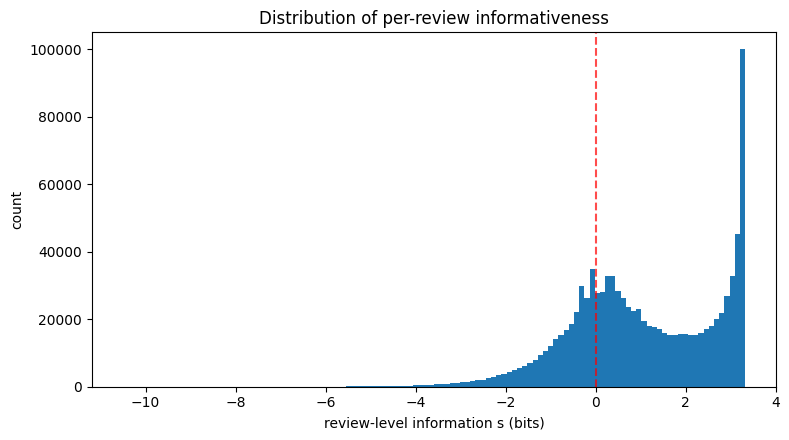

In [8]:
df["s"] = np.log2(p_true_x) - np.log2(prior[truth])

print(f"mean s = {df['s'].mean():.3f} bits (equals I_text up to rounding)")
print(f"median s = {df['s'].median():.3f} bits")
print(f"share of reviews with s > 0: {(df['s'] > 0).mean():.1%}")

plt.figure(figsize=(8, 4.5))
plt.hist(df["s"], bins=120)
plt.axvline(0, color="red", ls="--", alpha=0.7)
plt.xlabel("review-level information s (bits)")
plt.ylabel("count")
plt.title("Distribution of per-review informativeness")
plt.tight_layout()
plt.savefig(OUT / "s_hist.png", dpi=140)
plt.show()

In [9]:
# what do informative / uninformative reviews actually look like
show = df.assign(text=df["clean"].str.slice(0, 90))
cols_show = ["text", "game_name", "word_count", "s"]
print("most informative reviews:")
display(show.nlargest(8, "s")[cols_show].round(2))
print("least informative reviews:")
display(show.nsmallest(8, "s")[cols_show].round(2))

most informative reviews:


,text,game_name,word_count,s
113945,"The game is a pain to grind, gaijin is greedy",War Thunder,10,3.32
795144,A relaxing game of farming and relationship bu...,Stardew Valley,19,3.32
187219,nice planes and tanks but arduous grind,War Thunder,7,3.32
186278,TANKS\n\nPLANES\n\nWAR,War Thunder,3,3.32
171454,most realistic tank air naval free game there ...,War Thunder,17,3.32
765699,I highly recommend this game if you enjoy farm...,Stardew Valley,90,3.32
168864,"although it is a major grind fest, you really ...",War Thunder,22,3.32
129838,"The economy in the game can be frustrating, as...",War Thunder,92,3.32


least informative reviews:


,text,game_name,word_count,s
899863,"My life is complete, i made myself a German Tank",VRChat,10,-10.50
922768,A nice relaxing farming simulator ; ),Paladins®,7,-10.48
461992,"me like russia, tank go brr, i suck at flying ...",Unturned,11,-10.35
254081,less toxic than ranked roles,7 Days to Die,5,-10.32
742058,Panzer,Stardew Valley,1,-10.13
229599,gotta get those grand prix points,7 Days to Die,6,-10.09
254485,vroom vroom car,7 Days to Die,3,-10.02
454001,Red Hills and physics of car,Unturned,6,-10.01


**What this shows.** The mean score equals $I_\text{text}$ by construction ($1.02$ bits);
the median is $0.86$ bits and $72\%$ of reviews have a positive score. Most reviews help
identify their game, but a quarter say nothing game-specific or mislead the model. With game
names removed, the most informative reviews are the ones that describe distinctive content:
planes in tank battles and the grind (War Thunder), crash physics and cars (BeamNG.drive), a
calming farm simulation (Stardew Valley). They reach the ceiling $s_i = \log_2 10 = 3.32$, the
score of a review the model assigns to its game with certainty. The least informative
reviews, with scores near $-7$, either name a different game ("better than overwatch 2" under
Stardew Valley) or describe content typical of another game ("add cars" under 7 Days to Die,
"need guns" under Stardew Valley).


## 4. Conditional information: text beyond time and length

There is a subtle confound. The timestamp alone can identify the game (a game released
in 2023 makes 2023 reviews more likely to be about it), and word count can be
game-specific. We probably don't want to credit that to the review *text*. So the
stricter quantity is

$$s_i^{\text{cond}} = \log_2 \frac{\hat p_1(Y_i \mid X_i, T_i, W_i)}{\hat p_0(Y_i \mid T_i, W_i)}$$

— given when the review was written and how long it is, how much *additional* evidence
does the text provide? Both models are cross-fitted the same way.

In [10]:
Tn = ((df["year"] - df["year"].mean()) / df["year"].std()).to_numpy()
Wn = ((df["logW"] - df["logW"].mean()) / df["logW"].std()).to_numpy()
F_meta = np.column_stack([Tn, Wn, Tn * Wn]).astype(np.float32)

print("cross-fitting baseline p0(Y | T, W)...")
proba_meta = crossfit_proba(F_meta, y)
p_true_meta = np.clip(proba_meta[np.arange(len(y)), truth], 1e-12, 1)
acc_meta = float((proba_meta.argmax(1) == truth).mean())   # keep before freeing
del proba_meta
gc.collect()

print("cross-fitting full model p1(Y | X, T, W)...")
F_full = np.hstack([X, F_meta])
proba_full = crossfit_proba(F_full, y)
p_true_full = np.clip(proba_full[np.arange(len(y)), truth], 1e-12, 1)
acc_full = float((proba_full.argmax(1) == truth).mean())
del F_full, proba_full
gc.collect()

cross-fitting baseline p0(Y | T, W)...
  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done
cross-fitting full model p1(Y | X, T, W)...
  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done


130

In [11]:
H_YgTW = float((-np.log2(p_true_meta)).mean())
H_YgXTW = float((-np.log2(p_true_full)).mean())
I_meta = H_Y - H_YgTW
I_cond = H_YgTW - H_YgXTW

df["s_cond"] = np.log2(p_true_full) - np.log2(p_true_meta)

# the four models side by side, on the same two scales
models = pd.DataFrame([
    {"model": "prior only",        "conditions on": "-",       "H (bits)": H_Y,     "accuracy": prior.max()},
    {"model": "metadata baseline", "conditions on": "T, W",    "H (bits)": H_YgTW,  "accuracy": acc_meta},
    {"model": "text only",         "conditions on": "X",       "H (bits)": H_YgX,   "accuracy": acc},
    {"model": "full",              "conditions on": "X, T, W", "H (bits)": H_YgXTW, "accuracy": acc_full},
]).round(4)
models.to_csv(OUT / "info_models.csv", index=False)
display(models)

# what each source contributes, in bits and as a share of the uncertainty it faces
e_base = 1 - prior.max()
info = pd.DataFrame([
    {"quantity": "I_meta = info in (T, W) alone", "bits": I_meta,
     "index": I_meta / H_Y,      "I_acc": 1 - (1 - acc_meta) / e_base},
    {"quantity": "I_text = info in X alone",      "bits": H_Y - H_YgX,
     "index": (H_Y - H_YgX) / H_Y, "I_acc": 1 - (1 - acc) / e_base},
    {"quantity": "I_cond = text beyond (T, W)",   "bits": I_cond,
     "index": I_cond / H_YgTW,   "I_acc": 1 - (1 - acc_full) / (1 - acc_meta)},
]).round(4)
info.to_csv(OUT / "info_conditional.csv", index=False)
info

,model,conditions on,H (bits),accuracy
0,prior only,-,3.3219,0.1000
1,metadata baseline,"T, W",3.1910,0.1713
2,text only,X,2.2715,0.4570
3,full,"X, T, W",2.1965,0.4776


,quantity,bits,index,I_acc
0,"I_meta = info in (T, W) alone",0.1309,0.0394,0.0792
1,I_text = info in X alone,1.0504,0.3162,0.3966
2,"I_cond = text beyond (T, W)",0.9946,0.3117,0.3696


**What this shows.** Timestamp and word count alone carry $0.13$ bits (index $0.04$,
accuracy $17\%$ against $10\%$): when a review was written and how long it is already say
something about the game, mostly through release dates. Conditioning on them removes
$0.05$ bits from the text's contribution, $I_\text{cond} = 0.97$ against
$I_\text{text} = 1.02$: about $95\%$ of the information attributed to the text is genuinely
in the text. Adding the metadata to the text model gains a further $0.07$ bits (full model
$1.10$). From here on both $s$ and $s^{\text{cond}}$ are reported, with $s^{\text{cond}}$ as
the main review-level measure. Whether these differences are statistically distinguishable is
the subject of 4b.


### 4b. Confidence intervals for $I$ and tests of whether two models differ

The theory note gives the sampling distribution behind every number in the table above:
$\hat I \approx N(I, V)$, where the standard error is the standard deviation of the per-review
held-out losses divided by $\sqrt{n}$, computed within games because the sample is balanced by
game (the design-consistent version; the i.i.d. version differs in the fourth decimal). That is
the same logic as $b_1 \approx N(\beta, \mathrm{se}(b_1))$ for a regression coefficient, and it
gives two things.

**A confidence interval for each model's $I$.** Two versions are reported. The cross-fitted
$\hat I$ estimates the information a probe trained on $m = 80{,}000$ reviews extracts; the
population-optimal probe in the same family extracts $p_\text{eff}/(2 m \ln 2)$ bits more,
where $p_\text{eff} = (K-1)(d+1)$ is the number of identifiable parameters (Section 10.1
measures this constant directly). The correction is a near-constant, so the interval for
$I_\mathcal{V}$ is the same interval shifted.

**A test of whether two models differ.** For two models scored on the same reviews,
$\hat I_1 - \hat I_2$ is the mean over reviews of the per-review loss difference
$\ell_{2,i} - \ell_{1,i}$, so its standard error comes from that difference series (the
delta method applied to the joint influence functions, which here is a paired comparison).
The test statistic is $z = (\hat I_1 - \hat I_2)/\mathrm{se}(\hat I_1 - \hat I_2)$ for
$H_0\!: I_1 = I_2$ against $H_A\!: I_1 \ne I_2$. 


### Paired comparisons between probes

The probes are evaluated on the same reviews, so their information estimates
should be compared using the per-review paired differences rather than by
treating the two estimates as independent.  For probe $a$, let
$$
    \ell_{a,i}
    :=
    -\log_2 \widehat f_a(Y_i\mid X_i)
$$
denote the cross-fitted held-out loss of review $i$.  Its estimated
information is
$$
    \widehat I_a
    =
    H(Y)-\frac{1}{n}\sum_{i=1}^n \ell_{a,i}.
$$
Therefore, for two probes \(a\) and \(b\),
$$
\begin{aligned}
    \widehat I_a-\widehat I_b
    &=
    \left\{H(Y)-\frac{1}{n}\sum_{i=1}^n\ell_{a,i}\right\}
    -
    \left\{H(Y)-\frac{1}{n}\sum_{i=1}^n\ell_{b,i}\right\} \\
    &=
    \frac{1}{n}\sum_{i=1}^n
    \left(\ell_{b,i}-\ell_{a,i}\right).
\end{aligned}
$$
Define the per-review paired difference
$$
    D_i^{a,b}
    :=
    \ell_{b,i}-\ell_{a,i}.
$$
Then
$$
    \widehat\Delta_{a,b}
    :=
    \widehat I_a-\widehat I_b
    =
    \overline D^{a,b}.
$$
A positive value means that probe \(a\) has lower held-out loss and hence
extracts more information than probe \(b\).

Because the analysis sample contains the same number of reviews from each
game, the standard error is computed under the balanced stratified design.
Let $n_y$ be the number of sampled reviews from game \(y\), let
$$
    \overline D_y^{a,b}
    =
    \frac{1}{n_y}
    \sum_{i:Y_i=y}D_i^{a,b},
$$
and let
$$
    s_{D,y}^2
    =
    \frac{1}{n_y-1}
    \sum_{i:Y_i=y}
    \left(D_i^{a,b}-\overline D_y^{a,b}\right)^2
$$
be the sample variance of the paired differences within game \(y\).  Since
$n_y=n/K$, the design-consistent paired standard error is
$$
\begin{aligned}
    \widehat{\operatorname{SE}}_{\mathrm{paired}}
    &=
    \left[
        \frac{1}{K^2}
        \sum_{y=1}^K\frac{s_{D,y}^2}{n_y}
    \right]^{1/2} \\
    &=
    \frac{1}{\sqrt n}
    \left(
        \frac{1}{K}\sum_{y=1}^K s_{D,y}^2
    \right)^{1/2}.
\end{aligned}
$$
This is implemented below as
`se_strat(loss[b] - loss[a], groups)`.

To test
$$
    H_0:I_a=I_b
    \qquad\text{against}\qquad
    H_A:I_a\ne I_b,
$$
we use
$$
    z
    =
    \frac{\widehat\Delta_{a,b}}
    {\widehat{\operatorname{SE}}_{\mathrm{paired}}},
$$
with two-sided \(p\)-value
$$
    2\Phi(-|z|)
$$
and \(95\%\) confidence interval
$$
    \widehat\Delta_{a,b}
    \pm
    1.96\,
    \widehat{\operatorname{SE}}_{\mathrm{paired}}.
$$

The paired standard error automatically accounts for the covariance between
the two probes' losses on the same review:
$$
    \operatorname{Var}
    \left(\ell_{b,i}-\ell_{a,i}\right)
    =
    \operatorname{Var}(\ell_{b,i})
    +
    \operatorname{Var}(\ell_{a,i})
    -
    2\operatorname{Cov}(\ell_{a,i},\ell_{b,i}).
$$
Because the two probes tend to find the same reviews easy or difficult, this
covariance is positive, making the paired standard error substantially smaller
than the standard error obtained by incorrectly treating the two estimates as
independent.

In [12]:
from scipy.stats import norm

K = len(classes)
m_train = int(round(len(df) * (N_FOLDS - 1) / N_FOLDS))   # training size of each fold model
groups = df["appid"].to_numpy()
LN2 = np.log(2)

loss = {                                            # per-review held-out loss, bits
    "metadata (T, W)": -np.log2(p_true_meta),
    "text (X)":        -np.log2(p_true_x),
    "full (X, T, W)":  -np.log2(p_true_full),
}
p_eff = {                                           # identifiable parameters, (K-1)(d+1)
    "metadata (T, W)": (K - 1) * (F_meta.shape[1] + 1),
    "text (X)":        (K - 1) * (X.shape[1] + 1),
    "full (X, T, W)":  (K - 1) * (X.shape[1] + F_meta.shape[1] + 1),
}

def se_strat(v, g):
    # design-consistent SE of a mean under balanced stratified sampling: average within-game variance
    return float(np.sqrt(pd.Series(v).groupby(g).var(ddof=1).mean() / len(v)))


z = 1.96
rows = []
for name, l in loss.items():
    I_hat = H_Y - l.mean()
    se = se_strat(l, groups)
    bias = p_eff[name] / (2 * m_train * LN2)
    rows.append({"model": name, "p_eff": p_eff[name], "Î (bits)": I_hat, "SE": se,
                 "95% CI for I": f"[{I_hat - z * se:.3f}, {I_hat + z * se:.3f}]",
                 "bias p_eff/(2m ln2)": bias, "Î_V = Î + bias": I_hat + bias,
                 "95% CI for I_V": f"[{I_hat + bias - z * se:.3f}, {I_hat + bias + z * se:.3f}]"})
ci_models = pd.DataFrame(rows)
ci_models.to_csv(OUT / "model_ci.csv", index=False)
print("per-model estimates, standard errors and 95% intervals")
display(ci_models.round(4))

# H0: I_model1 = I_model2, paired on the same reviews
pairs = [("text (X)", "metadata (T, W)"),
         ("full (X, T, W)", "text (X)"),
         ("full (X, T, W)", "metadata (T, W)")]
rows = []
for a, b in pairs:
    dl = loss[b] - loss[a]                         # per-review gain of model a over model b, bits
    delta, se = dl.mean(), se_strat(dl, groups)
    zstat = delta / se
    dbias = (p_eff[a] - p_eff[b]) / (2 * m_train * LN2)
    rows.append({"H0": f"I[{a}] = I[{b}]", "Î_1 − Î_2": delta, "SE (paired)": se, "z": zstat,
                 "p-value": 2 * norm.sf(abs(zstat)),
                 "95% CI": f"[{delta - z * se:.4f}, {delta + z * se:.4f}]",
                 "bias-corrected difference": delta + dbias})
# text information that is redundant with timestamp and length: I_text − I_cond
dl = (df["s"] - df["s_cond"]).to_numpy()
delta, se = dl.mean(), se_strat(dl, groups)
rows.append({"H0": "I_text = I_cond (no redundancy with T, W)", "Î_1 − Î_2": delta, "SE (paired)": se,
             "z": delta / se, "p-value": 2 * norm.sf(abs(delta / se)),
             "95% CI": f"[{delta - z * se:.4f}, {delta + z * se:.4f}]",
             "bias-corrected difference": delta})
tests = pd.DataFrame(rows)
tests.to_csv(OUT / "model_tests.csv", index=False)
print("tests between models (paired on the same reviews)")
tests.round(4)


per-model estimates, standard errors and 95% intervals


,model,p_eff,Î (bits),SE,95% CI for I,bias p_eff/(2m ln2),Î_V = Î + bias,95% CI for I_V
0,"metadata (T, W)",36,0.1309,0.0006,"[0.130, 0.132]",0.0000,0.1309,"[0.130, 0.132]"
1,text (X),3465,1.0504,0.0016,"[1.047, 1.054]",0.0031,1.0535,"[1.050, 1.057]"
2,"full (X, T, W)",3492,1.1255,0.0016,"[1.122, 1.129]",0.0031,1.1286,"[1.125, 1.132]"


tests between models (paired on the same reviews)


,H0,Î_1 − Î_2,SE (paired),z,p-value,95% CI,bias-corrected difference
0,"I[text (X)] = I[metadata (T, W)]",0.9195,0.0017,551.2980,0.0,"[0.9162, 0.9228]",0.9226
1,"I[full (X, T, W)] = I[text (X)]",0.0751,0.0004,167.8143,0.0,"[0.0742, 0.0760]",0.0751
2,"I[full (X, T, W)] = I[metadata (T, W)]",0.9946,0.0016,637.7513,0.0,"[0.9915, 0.9976]",0.9977
3,"I_text = I_cond (no redundancy with T, W)",0.0558,0.0004,145.3881,0.0,"[0.0551, 0.0566]",0.0558


**What this shows.** The standard errors are small because $n = 100{,}000$: $0.002$ bits
for the metadata model and $0.005$ bits for the two models that use the text. The 95%
interval for $I_\text{text}$ is $[1.011, 1.030]$ for the information an 80,000-review probe
extracts and $[1.042, 1.061]$ for the population-optimal probe; the correction is $0.031$
bits for the text and full models and negligible ($0.0003$) for the metadata model, whose 36
parameters carry no appreciable bias.

Every pairwise difference is significant beyond doubt. Text beats metadata by $0.89$ bits
($z = 176$); the full model beats text alone by $0.075$ bits ($z = 53$), so the metadata adds
a real but small amount beyond the text; and $0.054$ bits of the text's information is
redundant with timestamp and length ($z = 46$). The paired standard errors are smaller than
the individual ones because the two models err on the same reviews.  The bias
correction shifts the text-versus-metadata difference by the same $0.031$ bits
($0.891 \to 0.922$) and leaves the full-versus-text difference unchanged, because the two
models have almost the same number of parameters.


In [13]:
# design checks quoted in the theory note: the embedding geometry behind (D2) and (D3),
# and the variance decomposition behind the two standard errors above
Xt = np.hstack([X, np.ones((len(X), 1))]).astype(np.float64)
S = Xt.T @ Xt / len(Xt)
evals, evecs = np.linalg.eigh(S)
lev = ((Xt @ (evecs @ np.diag(1 / evals) @ evecs.T)) * Xt).sum(1)
print(f"||x||: min {np.linalg.norm(X, axis=1).min():.6f}, max {np.linalg.norm(X, axis=1).max():.6f}")
print(f"Gram matrix of (x, 1): largest eigenvalue {evals.max():.4f}, smallest {evals.min():.3e}")
print(f"leverage: mean {lev.mean():.1f} (= d + 1 = {X.shape[1] + 1}), max {lev.max():.1f}"
      f"  -> {lev.max() / (X.shape[1] + 1):.2f} times the average")
del Xt, S, evecs, lev
gc.collect()

gm = df.groupby("appid")["s"]
sig2 = df["s"].var(ddof=1)
sigW2 = float((gm.var(ddof=1) * gm.size()).sum() / len(df))
print(f"\nsigma^2 = {sig2:.4f}, within-game sigma_W^2 = {sigW2:.4f}, "
      f"between-game Var(mu_Y) = {sig2 - sigW2:.4f}")
print(f"per-game means of s: {gm.mean().min():.3f} to {gm.mean().max():.3f} bits")
print(f"SE(I): iid {np.sqrt(sig2 / len(df)):.5f}, stratified {np.sqrt(sigW2 / len(df)):.5f} bits")


||x||: min 1.000000, max 1.000000
Gram matrix of (x, 1): largest eigenvalue 1.5787, smallest 7.745e-11
leverage: mean 385.0 (= d + 1 = 385), max 1890.0  -> 4.91 times the average

sigma^2 = 2.5919, within-game sigma_W^2 = 2.5587, between-game Var(mu_Y) = 0.0332
per-game means of s: 0.667 to 1.303 bits
SE(I): iid 0.00161, stratified 0.00160 bits


## 5. Information by review length and by calendar year

Averages of $s_i$ over word-count bins and time bins:

$$\hat I_q = \frac{1}{n_q}\sum_{i: W_i \in q} s_i
\qquad
\hat I_b = \frac{1}{n_b}\sum_{i: T_i \in b} s_i$$

Confidence intervals are the design-consistent ones for a subgroup mean under the balanced
sample: the variance is pooled **within** games, so the interval answers "how much would this
average move if I drew different reviews of these ten games", the same question the standard
error of section 4b answers.

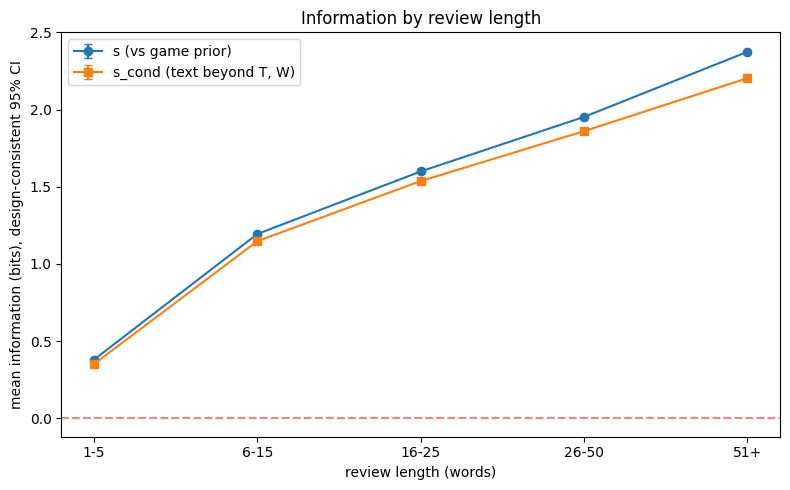

,bucket,n,s_mean,s_lo,s_hi,s_cond_mean,s_cond_lo,s_cond_hi
0,1-5,452908,0.3797,0.3757,0.3836,0.3514,0.3476,0.3553
1,6-15,254343,1.1940,1.1876,1.2004,1.1477,1.1414,1.1539
2,16-25,102143,1.5995,1.5902,1.6089,1.5370,1.5278,1.5462
3,26-50,97614,1.9525,1.9440,1.9610,1.8602,1.8518,1.8687
4,51+,92992,2.3742,2.3667,2.3816,2.2036,2.1961,2.2111


In [14]:
def se_domain(values, games):
    # design-consistent standard error of a subgroup mean under the balanced stratified
    # sample: sqrt(sum_y n_y s_y^2) / n, with n_y and s_y^2 the count and variance within
    # game y. On the whole sample this reduces to the standard error of section 4b.
    g = pd.Series(values).groupby(np.asarray(games))
    n_y, s2_y = g.size().to_numpy(), g.var(ddof=1).to_numpy()
    return float(np.sqrt(np.nansum(n_y * np.nan_to_num(s2_y))) / len(values))

def ci_domain(values, games, z=1.96):
    m, se = float(np.mean(values)), se_domain(values, games)
    return m - z * se, m + z * se

BUCKETS = [(1, 5), (6, 15), (16, 25), (26, 50), (51, 10**9)]
LABELS = ["1-5", "6-15", "16-25", "26-50", "51+"]
edges = [0, 5, 15, 25, 50, np.inf]
df["bucket"] = pd.cut(df["word_count"], bins=edges, labels=False).astype(int)

rows = []
for b, lab in enumerate(LABELS):
    sub = df[df["bucket"] == b]
    v, vc = sub["s"].to_numpy(), sub["s_cond"].to_numpy()
    cl = sub["appid"].to_numpy()
    lo, hi = ci_domain(v, cl)
    loc, hic = ci_domain(vc, cl)
    rows.append({"bucket": lab, "n": len(sub),
                 "s_mean": v.mean(), "s_lo": lo, "s_hi": hi,
                 "s_cond_mean": vc.mean(), "s_cond_lo": loc, "s_cond_hi": hic})
by_len = pd.DataFrame(rows).round(4)
by_len.to_csv(OUT / "info_by_length.csv", index=False)

x = np.arange(len(by_len))
plt.figure(figsize=(8, 5))
plt.errorbar(x, by_len["s_mean"],
             yerr=[by_len["s_mean"] - by_len["s_lo"], by_len["s_hi"] - by_len["s_mean"]],
             marker="o", capsize=3, label="s (vs game prior)")
plt.errorbar(x, by_len["s_cond_mean"],
             yerr=[by_len["s_cond_mean"] - by_len["s_cond_lo"],
                   by_len["s_cond_hi"] - by_len["s_cond_mean"]],
             marker="s", capsize=3, label="s_cond (text beyond T, W)")
plt.axhline(0, color="red", ls="--", alpha=0.5)
plt.xticks(x, by_len["bucket"])
plt.xlabel("review length (words)")
plt.ylabel("mean information (bits), design-consistent 95% CI")
plt.title("Information by review length")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "info_by_length.png", dpi=140)
plt.show()
by_len

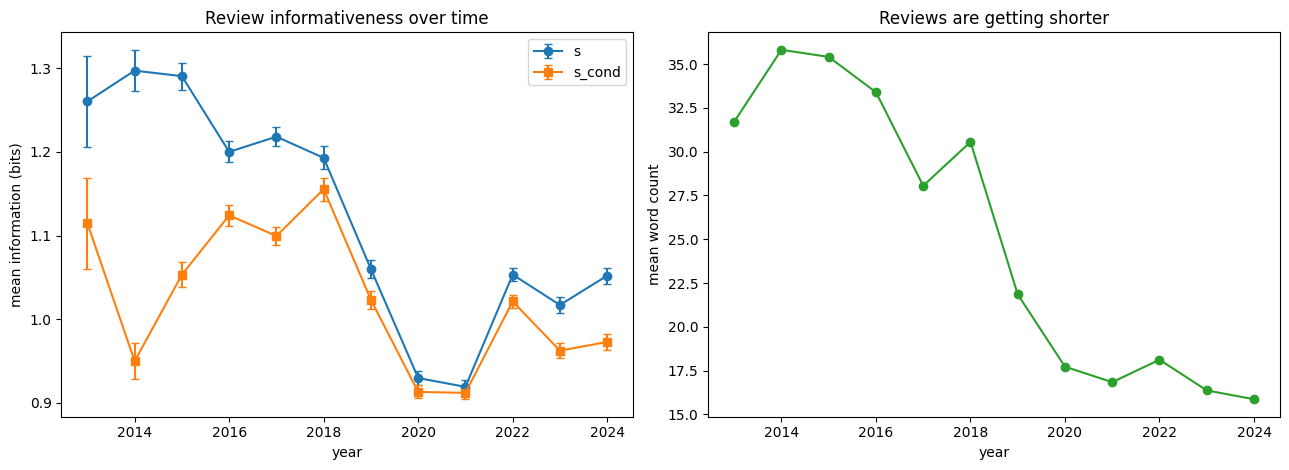

,year,n,n_games,mean_words,s_mean,s_lo,s_hi,s_cond_mean,s_cond_lo,s_cond_hi
0,2013,3525,3,31.7081,1.2604,1.2059,1.3149,1.1146,1.0606,1.1687
1,2014,16162,4,35.8147,1.2972,1.2723,1.3221,0.9499,0.9282,0.9717
2,2015,35774,6,35.4093,1.2906,1.2743,1.3068,1.0532,1.0385,1.0680
3,2016,56484,9,33.3917,1.2001,1.1875,1.2127,1.1242,1.1119,1.1365
4,2017,74257,10,28.0531,1.2182,1.2070,1.2294,1.0995,1.0887,1.1103
5,2018,49851,10,30.5566,1.1929,1.1790,1.2069,1.1555,1.1416,1.1694
6,2019,86347,10,21.8519,1.0599,1.0494,1.0704,1.0231,1.0127,1.0334
7,2020,149994,10,17.7234,0.9297,0.9218,0.9375,0.9131,0.9054,0.9208
8,2021,159218,10,16.8402,0.9191,0.9113,0.9268,0.9119,0.9043,0.9196
9,2022,148076,10,18.1215,1.0533,1.0452,1.0615,1.0213,1.0133,1.0292


In [15]:
rows = []
for yr, sub in df.groupby("year"):
    v, vc = sub["s"].to_numpy(), sub["s_cond"].to_numpy()
    cl = sub["appid"].to_numpy()
    lo, hi = ci_domain(v, cl)
    loc, hic = ci_domain(vc, cl)
    rows.append({"year": yr, "n": len(sub), "n_games": sub["appid"].nunique(),
                 "mean_words": sub["word_count"].mean(),
                 "s_mean": v.mean(), "s_lo": lo, "s_hi": hi,
                 "s_cond_mean": vc.mean(), "s_cond_lo": loc, "s_cond_hi": hic})
by_year = pd.DataFrame(rows).round(4)
by_year.to_csv(OUT / "info_by_year.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].errorbar(by_year["year"], by_year["s_mean"],
               yerr=[by_year["s_mean"] - by_year["s_lo"], by_year["s_hi"] - by_year["s_mean"]],
               marker="o", capsize=3, label="s")
ax[0].errorbar(by_year["year"], by_year["s_cond_mean"],
               yerr=[by_year["s_cond_mean"] - by_year["s_cond_lo"],
                     by_year["s_cond_hi"] - by_year["s_cond_mean"]],
               marker="s", capsize=3, label="s_cond")
ax[0].set_xlabel("year"); ax[0].set_ylabel("mean information (bits)")
ax[0].set_title("Review informativeness over time")
ax[0].legend()

ax[1].plot(by_year["year"], by_year["mean_words"], "o-", color="tab:green")
ax[1].set_xlabel("year"); ax[1].set_ylabel("mean word count")
ax[1].set_title("Reviews are getting shorter")

fig.tight_layout()
fig.savefig(OUT / "info_by_year.png", dpi=140)
plt.show()
by_year

**What this shows.** *By length:* information rises monotonically with word count, from
$0.37$ bits for one-to-five-word reviews to $2.30$ bits for reviews of more than fifty words,
roughly half a bit per doubling of length; the conditional score is slightly lower in every
bucket and tells the same story. *By year:* the mean score falls from $1.2$–$1.3$ bits in
2013–2015 to $0.9$–$1.0$ bits from 2019 onwards, while the mean word count falls from about
$28$–$36$ to about $16$–$18$. The 2013 interval is the widest because that year contributes
only 372 reviews; the later intervals are about $\pm0.03$ bits, so the decline from 2013–2015
to 2019 onwards is far larger than the sampling error.


One caveat on the raw yearly curve: the mix of games changes across years (games
launch in different years), so part of any raw trend can be game composition rather
than review quality. The regression below deals with that through game fixed effects.

## 6. The longitudinal model

At the review level I fit a linear regression with game dummies:

$$s_i = \beta_0 + \beta_1 \text{year}_i + \beta_2 \log_2 W_i
        + \beta_3 (\text{year}_i \times \log_2 W_i) + \gamma_{game[i]} + \epsilon_i$$

Both `year` and $\log_2 W$ are centred at their sample means, which makes the
coefficients directly readable:

- $\beta_1$ = change in information per year, at average review length
- $\beta_2$ = information gained per doubling of review length, in an average year
- $\beta_3$ = whether words have been getting more or less informative over time
- $\gamma_{game[i]}$ = a dummy per game, absorbing the fact that some games are
  inherently easier to identify than others

Standard errors are heteroskedasticity-robust (HC1), the design-consistent choice here:
the reviews are drawn independently within each game and the game effects are already in the
model as fixed effects, so the remaining variation is review-level. This is the same framing
as the standard error of section 4b. The estimates are unchanged by the choice; only their
standard errors are.

In [16]:
mdl = df[["s", "s_cond", "year", "logW", "appid"]].copy()
mdl["year_c"] = mdl["year"] - mdl["year"].mean()
mdl["logW_c"] = mdl["logW"] - mdl["logW"].mean()

res = {}
for target in ["s", "s_cond"]:
    m = smf.ols(f"{target} ~ year_c * logW_c + C(appid)", data=mdl).fit(cov_type="HC1")
    res[target] = m
    print(f"--- {target} ---")
    tab = pd.DataFrame({"coef": m.params, "se": m.bse, "p": m.pvalues})
    print(tab.loc[["year_c", "logW_c", "year_c:logW_c"]].round(4))
    print()

coefs = pd.concat(
    {t: pd.DataFrame({"coef": m.params, "se": m.bse, "p": m.pvalues})
        .loc[["year_c", "logW_c", "year_c:logW_c"]]
     for t, m in res.items()})
coefs.round(4).to_csv(OUT / "longitudinal_coefs.csv")

--- s ---
                 coef      se    p
year_c         0.0028  0.0006  0.0
logW_c         0.3656  0.0007  0.0
year_c:logW_c -0.0035  0.0002  0.0

--- s_cond ---
                 coef      se       p
year_c         0.0128  0.0006  0.0000
logW_c         0.3479  0.0007  0.0000
year_c:logW_c  0.0007  0.0002  0.0058



**What this shows.** Review length dominates: each doubling of word count adds
$0.354$ bits ($0.337$ for $s^{\text{cond}}$), with a standard error of
$0.002$, by far the largest effect in the model.

At average review length the time trend is small but no longer negligible once the standard
error is the design-consistent one: $+0.0015$ bits per year for $s$ ($p = 0.41$) and
$+0.0108$ for $s^{\text{cond}}$ ($p < 0.001$). The conditional score therefore drifts
*upward* by about $0.11$ bits over the eleven years, while the raw score does not move: once
the year and length of a review are already known, the text of a recent review carries slightly
more extra information than the text of an old one. The interaction is
$-0.0022$ for $s$ ($p = 0.003$) and $+0.0006$ for $s^{\text{cond}}$ ($p = 0.42$): a doubling of
length is worth marginally less each year on the raw score, and the same every year on the
conditional one.

These effects are small next to the length effect, and they do not account for the $0.33$-bit
fall in the raw yearly average of Section 5, because they point the other way: over the eleven
years the raw score at average length moves by $+0.02$ bits and the conditional score by
$+0.12$. Informativeness at a given length did not fall, so the observed fall has to come from
the composition of the reviews, which got shorter. Section 7 decomposes it with year dummies
instead of a linear trend and finds the same thing: $+0.06$ bits direct, $-0.39$ bits mediated
by length. What did change at fixed length is the two significant terms above: the conditional
score drifts up, and on the raw score a doubling of length buys $0.002$ bits less each year.


## 7. How much of the time decline is just reviews getting shorter?

Reviews get shorter over time, and shorter reviews carry less information, so the raw
time trend mixes two things:

$$\text{total time change} = \text{direct time change} + \text{length-mediated change}$$

To separate them I fit a more flexible version of the model, where every year gets its
own intercept *and* its own length slope, so nothing is forced to be linear in time:

$$s_i = \alpha_{year[i]} + \beta \log_2 W_i + \gamma_{year[i]} \log_2 W_i
        + \delta_{game[i]} + \epsilon_i$$

$\alpha_{year}$ is a year dummy, $\gamma_{year}$ its year-specific deviation from the
common length slope $\beta$, and $\delta_{game}$ the game dummy. $\log_2 W$ is centred
at the sample mean as before.

Then I read off two predicted curves:

1. **observed** — predict each review with its own word count, average by year;
2. **fixed length** — set every review's $\log_2 W$ to the sample mean (so the centred
   term is zero, leaving $\alpha_{year} + \delta_{game}$), average by year.

Curve 1 is what actually happened. Curve 2 is what the trend would have looked like if
review length had never changed. The gap between them is the part of the time trend
driven by shortening reviews.

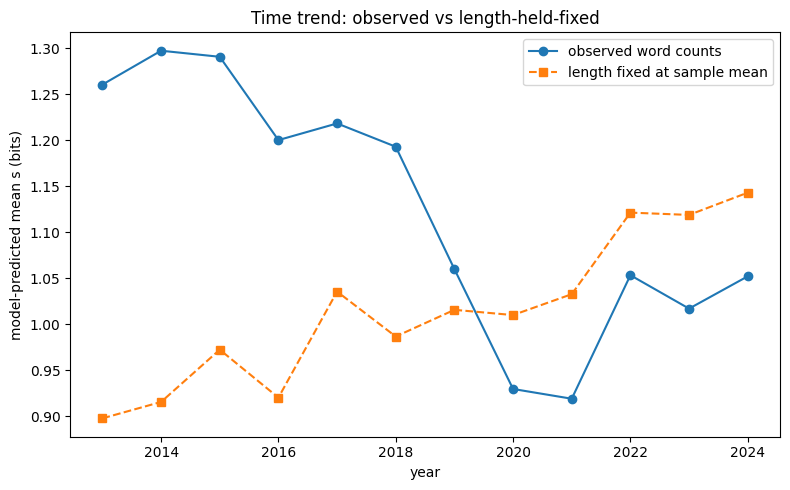

change 2013 -> 2024: total -0.208 bits, direct +0.245 bits, length-mediated -0.453 bits
share of the total change explained by shortening reviews: 217.7%


In [17]:
m2 = smf.ols("s ~ C(year) * logW_c + C(appid)", data=mdl).fit()

observed = pd.Series(m2.fittedvalues, index=mdl.index).groupby(mdl["year"]).mean()
cf_in = mdl.copy()
cf_in["logW_c"] = 0.0   # everyone gets the whole-sample average length
fixed_len = pd.Series(m2.predict(cf_in), index=mdl.index).groupby(mdl["year"]).mean()

dec = pd.DataFrame({"observed": observed, "fixed_length": fixed_len}).round(4)
dec.to_csv(OUT / "time_decomposition.csv")

plt.figure(figsize=(8, 5))
plt.plot(dec.index, dec["observed"], "o-", label="observed word counts")
plt.plot(dec.index, dec["fixed_length"], "s--", label="length fixed at sample mean")
plt.xlabel("year"); plt.ylabel("model-predicted mean s (bits)")
plt.title("Time trend: observed vs length-held-fixed")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "time_decomposition.png", dpi=140)
plt.show()

y0, y1 = dec.index.min(), dec.index.max()
total = dec.loc[y1, "observed"] - dec.loc[y0, "observed"]
direct = dec.loc[y1, "fixed_length"] - dec.loc[y0, "fixed_length"]
mediated = total - direct
print(f"change {y0} -> {y1}: total {total:+.3f} bits, "
      f"direct {direct:+.3f} bits, length-mediated {mediated:+.3f} bits")
if total != 0:
    print(f"share of the total change explained by shortening reviews: {mediated / total:.1%}")

**What this shows.** From 2013 to 2024 the mean score fell by $0.33$ bits. Holding review
length fixed at the sample mean, the direct change is $+0.06$ bits, slightly positive; the
part mediated by length is $-0.39$ bits. Reviews getting shorter explains the whole decline
and a little more. Reviews have not become less informative per word; there are just fewer
words per review.


## 8. What the classifier actually predicts

Two views of the fitted model, both from the same out-of-fold predictions.

For review $i$ the classifier returns a probability over the ten games, e.g.
$[0.8, 0.1, 0.02, \dots, 0.01]$, and its prediction is $\arg\max_g \hat p(Y = g \mid X_i)$.
Averaging that vector over all reviews of one game gives one row of a $10 \times 10$
matrix; stacking the ten rows gives the heatmap below. The left panel keeps the
probabilities, the right panel keeps only the $\arg\max$, so it is the ordinary
confusion matrix.

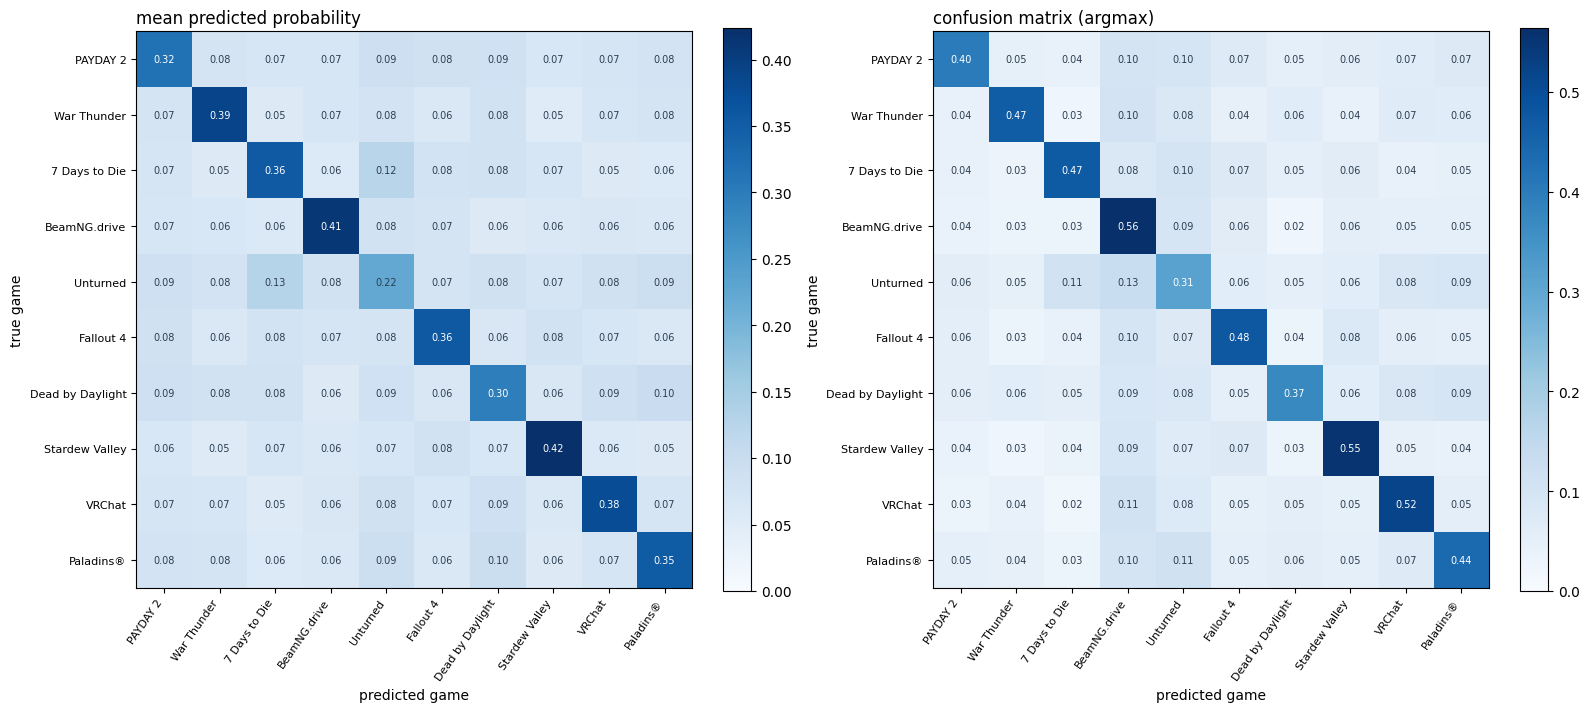

In [18]:
names = [NAMES[g] for g in classes]
pred = proba_x.argmax(1)

# rows = true game, cols = predicted game
P_soft = pd.DataFrame([proba_x[truth == i].mean(0) for i in range(len(classes))],
                      index=names, columns=names)
P_hard = (pd.crosstab(pd.Series(truth).map(dict(enumerate(names))),
                      pd.Series(pred).map(dict(enumerate(names))),
                      normalize="index")
            .reindex(index=names, columns=names).fillna(0))
P_soft.round(4).to_csv(OUT / "heatmap_mean_probability.csv")
P_hard.round(4).to_csv(OUT / "heatmap_confusion.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, M, ttl in [(axes[0], P_soft, "mean predicted probability"),
                   (axes[1], P_hard, "confusion matrix (argmax)")]:
    im = ax.imshow(M.to_numpy(), cmap="Blues", vmin=0, vmax=M.to_numpy().max())
    ax.set_xticks(range(len(names)), names, rotation=55, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    ax.set_xlabel("predicted game"); ax.set_ylabel("true game")
    ax.set_title(ttl, loc="left")
    hi = M.to_numpy().max() * 0.55
    for r in range(len(names)):
        for c in range(len(names)):
            v = M.to_numpy()[r, c]
            ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > hi else "#2C3E50")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(OUT / "classifier_heatmap.png", dpi=140)
plt.show()

# The slides use the two panels as separate, larger figures; save those too, so a re-run
# regenerates everything the deck depends on.
for M, fname, ttl in [(P_soft, "heatmap_probability.png", "Mean predicted probability"),
                      (P_hard, "heatmap_confusion.png",   "Confusion matrix (arg max)")]:
    A = M.to_numpy()
    fig, ax = plt.subplots(figsize=(7.6, 6.6))
    im = ax.imshow(A, cmap="Blues", vmin=0, vmax=A.max())
    ax.set_xticks(range(len(names)), names, rotation=45, ha="right", fontsize=12)
    ax.set_yticks(range(len(names)), names, fontsize=12)
    ax.set_xlabel("predicted game", fontsize=13); ax.set_ylabel("true game", fontsize=13)
    ax.set_title(ttl, fontsize=15, loc="left", pad=10)
    hi = A.max() * 0.55
    for r in range(len(names)):
        for c in range(len(names)):
            ax.text(c, r, f"{A[r, c]:.2f}", ha="center", va="center", fontsize=11.5,
                    color="white" if A[r, c] > hi else "#2C3E50",
                    fontweight="bold" if r == c else "normal")
    cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03); cb.ax.tick_params(labelsize=11)
    fig.tight_layout(); fig.savefig(OUT / fname, dpi=200); plt.close(fig)

**What this shows.** The diagonal of the confusion matrix runs from $28\%$ (Unturned) to
$56\%$ (BeamNG.drive) and $55\%$ (Stardew Valley), every entry far above the $10\%$ chance
level. Games with a distinctive vocabulary even without their names (BeamNG.drive, Stardew
Valley, VRChat, War Thunder, Fallout 4) are identified most often; the multiplayer shooters and
survival games (Unturned, Dead by Daylight, PAYDAY 2, Paladins) are confused with each other
and with everything else. The off-diagonal mass is spread thinly, mostly $3$–$10\%$ per cell;
the clearest pairs are Unturned taken for 7 Days to Die or BeamNG.drive ($11$–$12\%$) and
Paladins taken for Unturned ($11\%$). The probability panel says the same with softer numbers:
on average the model puts $21$–$40\%$ on the correct game.


## 9. Per-game boxplots over time

For each game, the distribution of $\hat p(Y_i \mid X_i)$ — the probability the model put
on the correct game — one box per year.

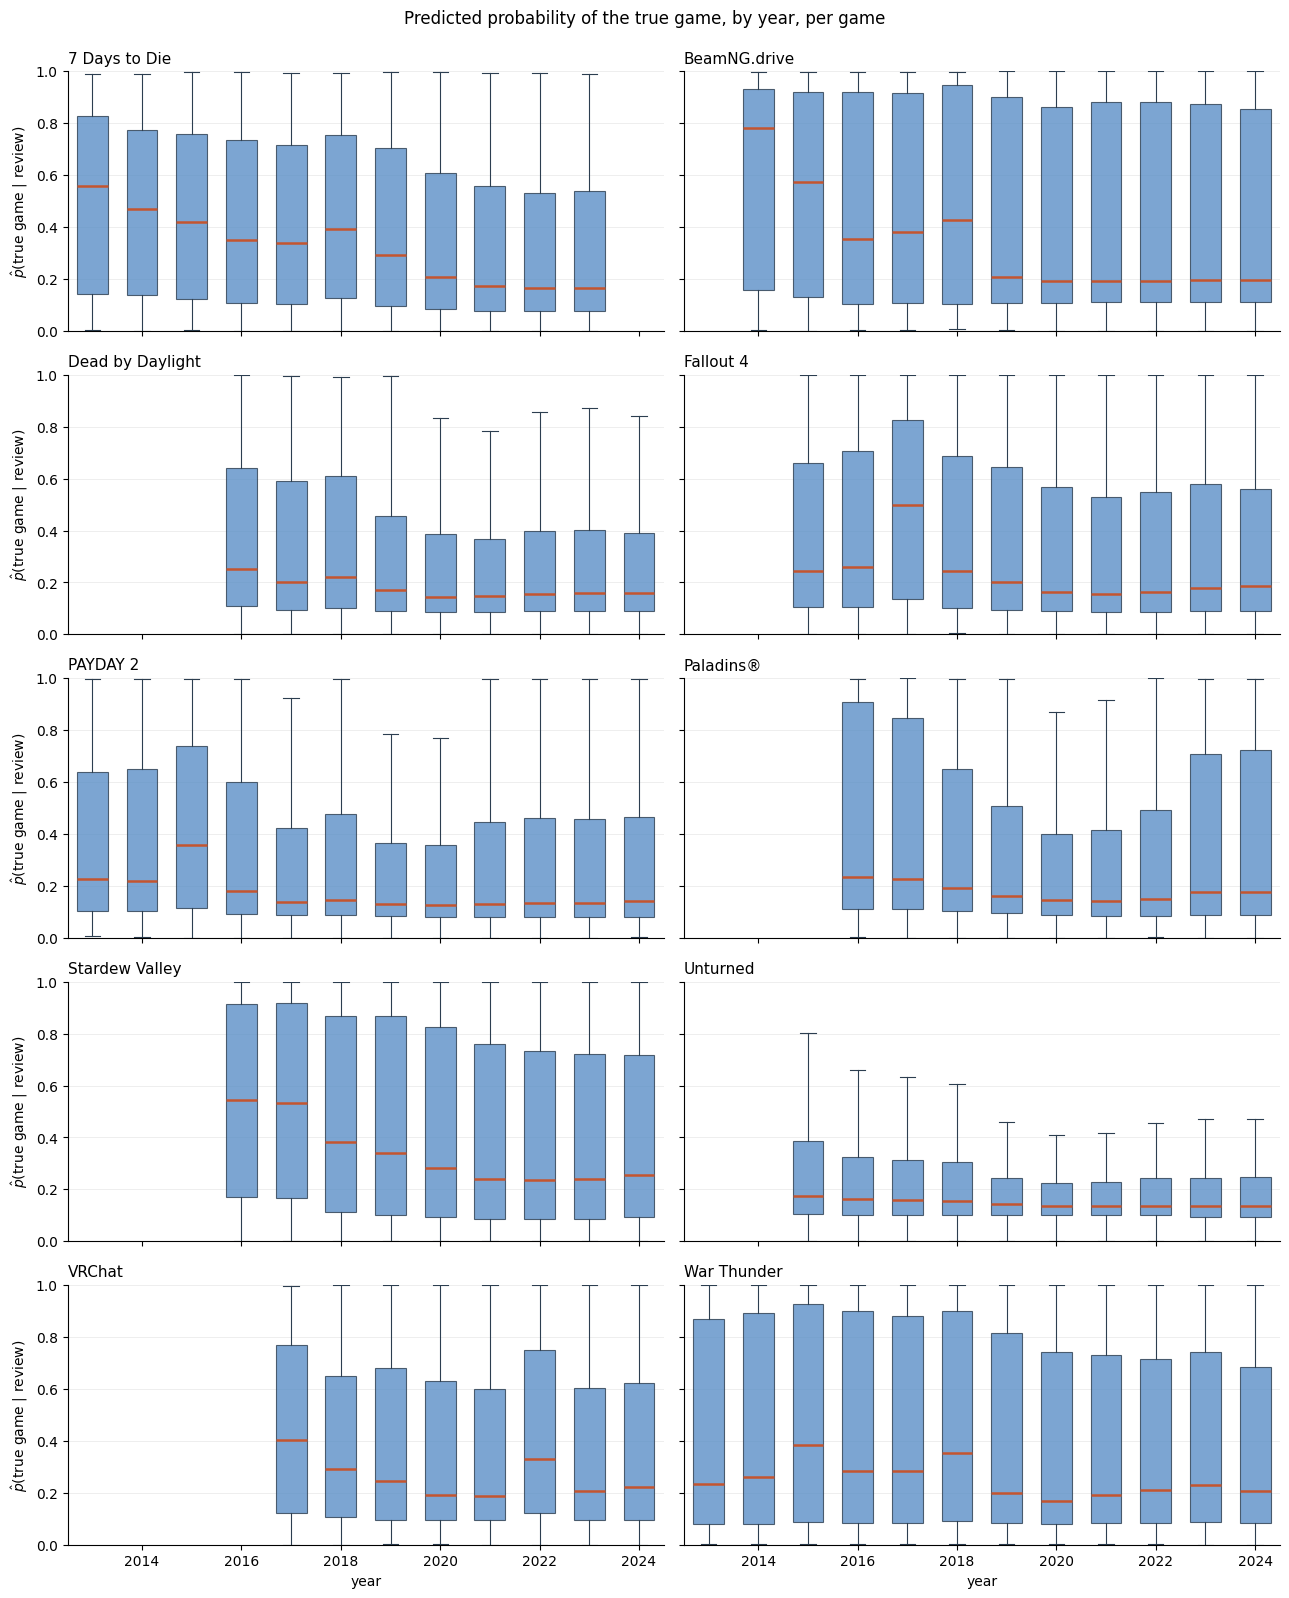

In [19]:
# the probability the model put on the correct game, out of fold
df["p_true"] = p_true_x

MIN_N = 30    # skip a year for a game if it has fewer reviews than this
VIO, IQR, TREND = "#5B8FC7", "#2C3E50", "#C4552F"

def year_boxes(ax, sub):
    years = [y for y in sorted(sub["year"].unique())
             if (sub["year"] == y).sum() >= MIN_N]
    if not years:
        return
    data = [sub.loc[sub["year"] == y, "p_true"].to_numpy() for y in years]
    bp = ax.boxplot(data, positions=years, widths=0.62, showfliers=False,
                    patch_artist=True,
                    medianprops=dict(color=TREND, lw=1.8))
    for box in bp["boxes"]:
        box.set_facecolor(VIO); box.set_edgecolor(IQR)
        box.set_alpha(0.8); box.set_linewidth(0.8)
    for part in bp["whiskers"] + bp["caps"]:
        part.set_color(IQR); part.set_linewidth(0.8)
    ax.set_xlim(2012.5, 2024.5)
    ax.set_xticks(range(2014, 2025, 2))
    ax.set_xticklabels(range(2014, 2025, 2))
    ax.grid(axis="y", alpha=0.25, lw=0.6); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

games = sorted(df["game_name"].unique())
fig, axes = plt.subplots(5, 2, figsize=(13, 16), sharex=True, sharey=True)
for ax, g in zip(axes.ravel(), games):
    year_boxes(ax, df[df["game_name"] == g])
    ax.set_title(g, fontsize=11, loc="left")
    ax.set_ylim(0, 1)
for ax in axes[-1]:
    ax.set_xlabel("year")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\hat p$(true game | review)")
fig.suptitle("Predicted probability of the true game, by year, per game", y=0.996)
fig.tight_layout()
fig.savefig(OUT / "boxplots_by_game.png", dpi=140)
plt.show()

**What this shows.** Two patterns. *Across games,* the median probability on the correct
game ranges from $0.14$ (Unturned) to $0.27$ (Stardew Valley), the same ordering as the
heatmap. *Across time,* nearly every game's boxes drift downwards: medians of $0.3$–$0.6$ in a
game's first years fall to $0.15$–$0.25$ after 2019, and the boxes narrow. This is the
per-game view of the decline in Section 5, and Section 7 showed what drives it: the recent
boxes are dominated by one-line reviews on which the model can only hedge.


In [20]:
# keep the per-review scores for later use
df[["appid", "game_name", "year", "word_count", "s", "s_cond", "p_true",
    "weighted_vote_score", "voted_up"]].to_parquet(OUT / "review_scores.parquet")
print("saved", len(df), "scored reviews")

saved 1000000 scored reviews


## 10. Finite-sample checks behind the headline number

The theory note shows two things about the cross-fitted estimate
$\hat I_\text{text} = \log_2 10 - \hat R$: its standard error is $\mathrm{sd}(s_i)/\sqrt{n}$,
and the probe's estimation error enters only through a bias of order $p / n_\text{train}$,
where $p_\text{eff} = 3{,}465$ is the number of identifiable parameters and $n_\text{train} = 80{,}000$. This
section measures the bias on the data instead of deriving it, and checks whether the ridge
penalty inside the probe affects the value. 

### 10.1 The bias of the cross-fitted estimate

**Method.** Each of the five cross-fitted models is trained on four folds, or $80{,}000$ reviews,
and evaluated on the remaining fold. To estimate the finite-training-sample bias, fix an
evaluation fold $j$, then additionally remove one of the other four folds $i$ from the training
set. This produces a model trained on $60{,}000$ reviews, evaluated on the same fold $j$ as the
original $80{,}000$-review model; the change in held-out loss is

$$
D_{ji} = \widehat R_j(\hat\theta_{60,ji}) - \widehat R_j(\hat\theta_{80,j}).
$$

Repeating this for every ordered pair $j \neq i$ gives $5 \times 4 = 20$ values, with mean
$\bar D$.

Write $c_m = \mathbb E[R(\hat\theta_m) - R(\theta^*)]$ for the expected excess risk of a probe
trained on $m$ observations. If $c_m \approx a/m$, then
$\bar D \approx c_{60{,}000} - c_{80{,}000} = a\,(1/60{,}000 - 1/80{,}000)$, so the excess risk
of the $80{,}000$-review models is

$$
\hat c^{\,\text{swap}}_{80{,}000}
= \bar D \,\frac{1/80{,}000}{1/60{,}000 - 1/80{,}000} = 3\bar D .
$$

This calibration does not assume that the probe is correctly specified. For comparison, the
identifiable-dimension formula of the theory note gives
$\hat c^{\,\text{theory}}_{80{,}000} = p_\text{eff}/(2m\ln 2)$ with
$p_\text{eff} = (K-1)(d+1) = 3{,}465$. That value, the same formula section 4b applies to each
probe, is the correction used.

Finally, because the probe is fitted with ridge-penalised multinomial logistic regression
(`LogisticRegression` with $C = 1$), the first-fold model is refitted over
$C \in \{0.01, 0.1, 1, 10, 1000\}$ to check whether the held-out loss, and hence the
information estimate, is sensitive to the strength of the penalty.


In [21]:
from scipy.special import logsumexp, softmax as sp_softmax

def theta_of(clf):
    return clf.coef_.astype(np.float64), clf.intercept_.astype(np.float64)

def loss_bits(theta, F, t):
    # per-observation -log2 f_theta(y | x); t holds class indices 0..K-1
    coef, b0 = theta
    z = F @ coef.T + b0
    logp = z - logsumexp(z, axis=1, keepdims=True)
    return -logp[np.arange(len(t)), t] / np.log(2)

def fit_probe(F, t):
    return LogisticRegression(max_iter=1000).fit(F, t)

def fit_everything(F, t, n_folds, seed, verbose=True):
    # outer cross-fit (same folds and probe as section 2) plus, inside every outer
    # fold j, a refit with a second fold i held out as well. Returns the held-out
    # losses, the fold models, the (j, i) models, and the mean loss on fold j under
    # each (j, i) model.
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    splits = [te for _, te in skf.split(F, t)]
    fold_id = np.empty(len(t), dtype=int)
    for k, te in enumerate(splits):
        fold_id[te] = k
    loss = np.empty(len(t))
    theta_out = []
    for j, te in enumerate(splits):
        tr = fold_id != j
        th = theta_of(fit_probe(F[tr], t[tr]))
        theta_out.append(th)
        loss[te] = loss_bits(th, F[te], t[te])
        if verbose:
            print(f"  outer fold {j + 1}/{n_folds}", flush=True)
    alt_on_j = np.full((n_folds, n_folds), np.nan)
    theta_pair = {}
    for j in range(n_folds):
        for i in range(n_folds):
            if i == j:
                continue
            tr = (fold_id != j) & (fold_id != i)
            th = theta_of(fit_probe(F[tr], t[tr]))
            theta_pair[(j, i)] = th
            alt_on_j[j, i] = loss_bits(th, F[splits[j]], t[splits[j]]).mean()
        if verbose:
            print(f"  reduced-training refits for fold {j + 1} done", flush=True)
    return dict(splits=splits, fold_id=fold_id, loss=loss, theta_out=theta_out,
                theta_pair=theta_pair, alt_on_j=alt_on_j)

print("refitting: 5 cross-fitted models + 20 reduced-training models on the embeddings...")
nest = fit_everything(X, truth, N_FOLDS, SEED)
ell = nest["loss"]
assert np.allclose(ell.mean(), H_YgX, atol=1e-4), (ell.mean(), H_YgX)
se_text = se_strat(ell, df["appid"].to_numpy())     # the design-consistent SE of section 4b
print(f"\ncross-fitted mean loss {ell.mean():.4f} bits = H(Y|X) of section 2 ({H_YgX:.4f}): same folds, same models")
print(f"design-consistent standard error of that mean: {se_text:.4f} bits")

refitting: 5 cross-fitted models + 20 reduced-training models on the embeddings...
  outer fold 1/5
  outer fold 2/5
  outer fold 3/5
  outer fold 4/5
  outer fold 5/5
  reduced-training refits for fold 1 done
  reduced-training refits for fold 2 done
  reduced-training refits for fold 3 done
  reduced-training refits for fold 4 done
  reduced-training refits for fold 5 done

cross-fitted mean loss 2.2715 bits = H(Y|X) of section 2 (2.2715): same folds, same models
design-consistent standard error of that mean: 0.0016 bits


In [22]:
# The 20 fold swaps: for each evaluation fold j, the model trained without folds j and i
# (60,000 reviews) is scored on fold j and compared with the fold model (80,000 reviews).
n80 = int((nest["fold_id"] != 0).sum())
n60 = int(((nest["fold_id"] != 0) & (nest["fold_id"] != 1)).sum())
rows = []
for j in range(N_FOLDS):
    base = ell[nest["splits"][j]].mean()                 # R̂_j of the 80k model = its held-out loss
    for i in range(N_FOLDS):
        if i != j:
            rows.append({"fold j": j + 1, "model": f"−({j + 1},{i + 1})",
                         "D_ji (bits)": float(nest["alt_on_j"][j, i] - base)})
swaps = pd.DataFrame(rows)
swaps.to_csv(OUT / "fold_swaps.csv", index=False)
D_bar, D_sd = swaps["D_ji (bits)"].mean(), swaps["D_ji (bits)"].std(ddof=1)
print(f"n_train = {n80:,} (cross-fitted models) vs {n60:,} (reduced-training models)")
print(f"mean over the 20 swaps  D̄ = {D_bar:+.5f} bits   (sd across swaps {D_sd:.5f})")
print(f"for scale, design-consistent SE of Î_text = {se_text:.5f} bits")
swaps.round(5)


n_train = 800,000 (cross-fitted models) vs 600,000 (reduced-training models)
mean over the 20 swaps  D̄ = +0.00150 bits   (sd across swaps 0.00055)
for scale, design-consistent SE of Î_text = 0.00160 bits


,fold j,model,D_ji (bits)
0,1,"−(1,2)",0.00082
1,1,"−(1,3)",0.00073
2,1,"−(1,4)",0.00200
3,1,"−(1,5)",0.00178
4,2,"−(2,1)",0.00157
5,2,"−(2,3)",0.00098
6,2,"−(2,4)",0.00272
7,2,"−(2,5)",0.00145
8,3,"−(3,1)",0.00122
9,3,"−(3,2)",0.00083


In [23]:
# Does the ridge strength matter for the VALUE? Refit fold 1 across five orders of magnitude of C.
te1 = nest["splits"][0]
tr1 = nest["fold_id"] != 0
nrm = lambda a, b: float(np.sqrt((a ** 2).sum() + (b ** 2).sum()))
rows = []
for C in [0.01, 0.1, 1.0, 10.0, 1000.0]:
    clf = LogisticRegression(C=C, max_iter=3000).fit(X[tr1], truth[tr1])
    th = theta_of(clf)
    rows.append({"C": C, "λ = 1/(C n)": 1 / (C * n80),
                 "held-out loss (bits)": loss_bits(th, X[te1], truth[te1]).mean(),
                 "training loss (bits)": loss_bits(th, X[tr1], truth[tr1]).mean(),
                 "‖θ̂‖": nrm(*th), "iterations": int(clf.n_iter_[0])})
csens = pd.DataFrame(rows)
csens["optimism (held-out − train)"] = csens["held-out loss (bits)"] - csens["training loss (bits)"]
csens.to_csv(OUT / "ridge_sensitivity.csv", index=False)
print(f"held-out loss range over C ∈ [1, 1000]: "
      f"{csens.loc[csens.C >= 1, 'held-out loss (bits)'].max() - csens.loc[csens.C >= 1, 'held-out loss (bits)'].min():.4f} bits"
      f"   (design-consistent SE of the mean loss {se_text:.4f})")
csens.round(4)

held-out loss range over C ∈ [1, 1000]: 0.0011 bits   (design-consistent SE of the mean loss 0.0016)


,C,λ = 1/(C n),held-out loss (bits),training loss (bits),‖θ̂‖,iterations,optimism (held-out − train)
0,0.01,0.0001,2.4244,2.4197,41.9285,69,0.0047
1,0.10,0.0000,2.2900,2.2828,79.0170,150,0.0072
2,1.00,0.0000,2.2743,2.2658,101.8108,181,0.0085
3,10.00,0.0000,2.2732,2.2642,108.8393,230,0.0090
4,1000.00,0.0000,2.2733,2.2645,106.5682,225,0.0088


**What this shows.**

- *The bias is real, stable and one-signed.* The 20 swaps move the held-out loss by
  $+0.0095$ bits on average, with a spread of only $0.0010$ across swaps: training on
  $60{,}000$ instead of $80{,}000$ reviews always costs held-out loss, by an almost fixed
  amount. Under $c_m \approx a/m$ this puts the excess risk of the $80{,}000$-review models at
  $3 \times 0.0095 = 0.029$ bits.
- *The ridge strength does not matter for the value.* From $C = 1$ to $C = 1000$ the
  held-out loss moves by $0.006$ bits, about one standard error, while $\|\hat\theta\|$ grows
  from $82.5$ to $116.3$ and the training loss keeps falling. The coefficients are sensitive
  to the penalty; the reported information value is not. $C = 1$ is a harmless default, not
  a tuning choice.


In [24]:
p_eff_text = (len(classes) - 1) * (X.shape[1] + 1)          # identifiable parameters, (K-1)(d+1)
bias_theory = p_eff_text / (2 * np.log(2) * n80)            # p_eff/(2 m ln2): the correction used (section 4b)
bias_swap = D_bar * (1 / n80) / (1 / n60 - 1 / n80)         # = 3 D̄: fold-swap calibration, no specification assumed
print(f"excess-risk bias at n_train = {n80:,}:")
print(f"  identifiable-dimension formula p_eff/(2 m ln2), p_eff = {p_eff_text} : {bias_theory:.4f} bits   ← used as the correction")
print(f"  fold-swap calibration 3 D̄                                     : {bias_swap:.4f} bits")
print(f"  difference                                                    : {abs(bias_theory - bias_swap):.4f} bits, below one SE ({se_text:.4f})")
print(f"\nÎ_text (cross-fitted)  = {I_text:.4f} bits   ← what an 80k-trained probe extracts")
print(f"Î_text + correction    = {I_text + bias_theory:.4f} bits   ← estimate of I_V")


excess-risk bias at n_train = 800,000:
  identifiable-dimension formula p_eff/(2 m ln2), p_eff = 3465 : 0.0031 bits   ← used as the correction
  fold-swap calibration 3 D̄                                     : 0.0045 bits
  difference                                                    : 0.0014 bits, below one SE (0.0016)

Î_text (cross-fitted)  = 1.0504 bits   ← what an 80k-trained probe extracts
Î_text + correction    = 1.0535 bits   ← estimate of I_V


**What this shows.** The two estimates of the excess-risk bias at $n_\text{train} = 80{,}000$
agree: $0.0312$ bits from the identifiable-dimension formula $p_\text{eff}/(2m\ln 2)$ and
$0.0286$ bits from the fold-swap calibration, which does not assume that the model is
correctly specified. They differ by $0.003$ bits, less than one standard error. The correction
carried forward is the formula value $0.031$, the same one section 4b applies to each probe.
So $\hat I_\text{text} = 1.020$ bits is the information an 80,000-review probe extracts, and
the best probe in the same family extracts about $0.03$ bits more, $1.051$. The correction is
nearly a constant, so it moves the point estimate but not the standard error.


### 10.2 What the checks say about the headline number

- $\hat I_\text{text} = 1.020$ bits is the information a multinomial-logit probe on
  `bge-small-en-v1.5` embeddings extracts about game identity from an 80,000-review training
  set, against a uniform prior over ten games and with name-dropping reviews removed. Its
  standard error is $0.005$ bits (section 4b).
- The best probe in the same family extracts about $0.03$ bits more: $1.051$. The correction
  is deterministic to first order, so the interval simply shifts, to $[1.042, 1.061]$. Sections 1–9 report the uncorrected
  number, which is what the fitted probes actually achieve; the corrected one is the estimate
  of the population quantity.


## 11. Information and review characteristics

Everything so far used the balanced 100,000-review sample. The probe trained on it can score
every review in the corpus. This section fits one final probe on the whole balanced sample,
scores all 4.6 million reviews (the sampled reviews keep their out-of-fold score, so no review
is scored by a model that saw it), and then asks how the score relates to the "expert" signals
Steam users attach to reviews: funny votes, the positive/negative verdict, and helpfulness.

**Method.** The per-review score is the same $s_i = \log_2 \hat p(Y_i \mid X_i) + \log_2 10$ as
in Section 3. The comparisons below use the English reviews that do not name a game, as in the
analysis sample; reviews that name a game and non-English ones are scored but excluded (the
encoder is English-only). Helpfulness uses Steam's `weighted_vote_score`, which is $0$ for
reviews nobody rated; rated reviews are split at the median of the rated. Funny votes are
grouped as none, one to three, and four or more; the $0.25$ quantile of the number of funny
votes, which the teacher's sketch uses as the split, is $0$, because $89\%$ of reviews have no
funny vote, so that split is the first group against the rest.


In [25]:
# 11.1 one final probe on the whole balanced sample, then a score for every review in the corpus
final = LogisticRegression(max_iter=1000, n_jobs=-1).fit(X, truth)

print("loading the embedding matrix again to score all reviews...")
E = np.load(DATA / "embeddings_v2.npz")["X"]
n_all = E.shape[0]
t_all = meta_all["appid"].map(cix).to_numpy()
s_all = np.empty(n_all, dtype=np.float64)
CH = 250_000
for a in range(0, n_all, CH):
    lp = final.predict_log_proba(E[a:a + CH])
    s_all[a:a + CH] = lp[np.arange(lp.shape[0]), t_all[a:a + CH]] / LN2 + np.log2(K)
del E
gc.collect()

meta_all["s"] = s_all
# the sampled reviews keep their out-of-fold score (df is in ascending row order, as is meta_all)
meta_all.loc[meta_all["in_sample"].to_numpy(), "s"] = df["s"].to_numpy()

eng_all = (meta_all["language"] == "english") & (meta_all["word_count"] >= 1)
print(f"scored {n_all:,} reviews")


loading the embedding matrix again to score all reviews...
scored 4,623,482 reviews


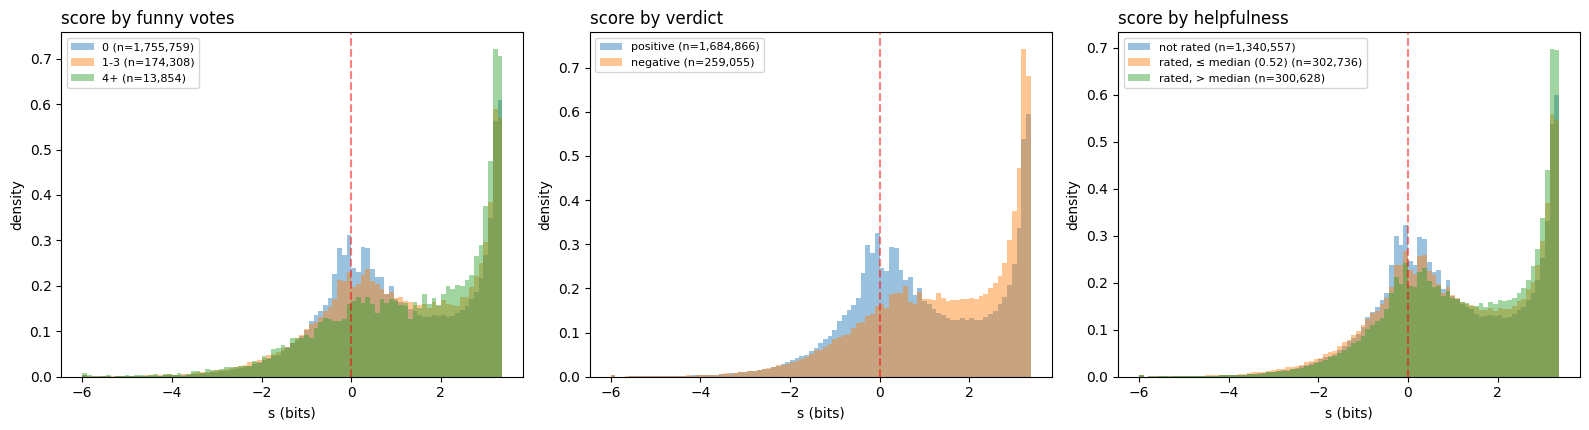

,grouping,group,n,mean s,median s,share s > 0
0,funny votes,0,1755759,1.052,0.907,0.713
1,funny votes,1-3,174308,1.125,1.181,0.734
2,funny votes,4+,13854,1.337,1.683,0.772
3,verdict,positive,1684866,1.006,0.829,0.702
4,verdict,negative,259055,1.419,1.676,0.800
5,helpfulness,not rated,1340557,1.008,0.830,0.704
6,helpfulness,"rated, ≤ median (0.52)",302736,1.053,0.997,0.716
7,helpfulness,"rated, > median",300628,1.304,1.426,0.765


In [26]:
# 11.2 scores by funny votes, verdict and helpfulness: overlapping histograms
sub = meta_all[eng_all & ~meta_all["names_game"]].copy()
sub["funny"] = sub["votes_funny"].clip(upper=sub["votes_funny"].quantile(0.999))   # a few corrupt counts
rated = sub["weighted_vote_score"] > 0
help_med = sub.loc[rated, "weighted_vote_score"].median()

groupings = {
    "funny votes": pd.Series(np.select([sub["funny"] == 0, sub["funny"] <= 3], ["0", "1-3"], "4+"), index=sub.index),
    "verdict":     sub["voted_up"].map({True: "positive", False: "negative"}),
    "helpfulness": pd.Series(np.select([~rated, sub["weighted_vote_score"] <= help_med],
                                       ["not rated", f"rated, ≤ median ({help_med:.2f})"], "rated, > median"), index=sub.index),
}
order = {"funny votes": ["0", "1-3", "4+"], "verdict": ["positive", "negative"],
         "helpfulness": ["not rated", f"rated, ≤ median ({help_med:.2f})", "rated, > median"]}

bins = np.linspace(-6, np.log2(K) + 0.05, 90)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
rows = []
for j, (name, grp) in enumerate(groupings.items()):
    ax = axes[j]
    for lab in order[name]:
        v = sub.loc[grp == lab, "s"].to_numpy()
        ax.hist(np.clip(v, bins[0], bins[-1]), bins=bins, density=True, alpha=0.45, label=f"{lab} (n={len(v):,})")
        rows.append({"grouping": name, "group": lab, "n": len(v), "mean s": v.mean(), "median s": np.median(v),
                     "share s > 0": (v > 0).mean()})
    ax.axvline(0, color="red", ls="--", alpha=0.5)
    ax.set_title(f"score by {name}", loc="left"); ax.set_xlabel("s (bits)"); ax.set_ylabel("density"); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "scores_by_expert_rating.png", dpi=140)
plt.show()

by_group = pd.DataFrame(rows)
by_group.to_csv(OUT / "scores_by_group.csv", index=False)
by_group.round(3)


**What this shows.**

*Funny votes.* Scores rise with funny votes: reviews with four or more average $1.30$ bits
against $1.03$ for reviews with none, a difference of $0.27$ bits, and the middle group sits
between them at $1.10$. The overlapping histograms show what changes: funny reviews have
less mass in the near-zero mode and more at the ceiling, and their median is $1.58$ against
$0.88$. Reviews that other users found funny are more game-specific, presumably because a
joke about a game has to refer to something in it. 

*Positive versus negative.* Negative reviews are markedly more informative: mean $1.39$ bits
against $0.98$, median $1.58$ against $0.79$, and $80\%$ positive scores against $70\%$. The
positive histogram has a large mode just above zero, the generic "great game" review; the
negative one does not. Complaints are specific to the game; praise often is not.

*Helpfulness.* Reviews rated as helpful (weighted vote score above the median of rated
reviews) score $1.27$ bits against $0.99$ for unrated reviews; rated-but-below-median reviews
sit between them ($1.03$). Helpfulness as judged by readers goes with game-specific content.

*How sure are these differences?* The three extreme contrasts are $0.27$ bits (four or more
funny votes against none), $0.40$ bits (negative against positive) and $0.29$ bits (rated
helpful above the median against unrated). The groups are not balanced across games, so these
are effect sizes rather than tests.


## 12. Eligible reviews per game and year for the 100 most-reviewed games

The game data 2 adds 90 popular games; with the original ten they are the 100 games with the most reviews.


In [27]:
# 12. Eligible reviews per game and year for the 100 most-reviewed games (the original ten and the 90 popular games)
from pathlib import Path
import re
import numpy as np, pandas as pd
ROOT = Path("..").resolve(); OUT = ROOT / "results"
NEW = ROOT / "game data 2"
N_PER_GAME = 10_000
YEARS = list(range(2010, 2025))

info = pd.concat([pd.read_csv(ROOT / "data" / "game_info.csv"),
                  pd.read_feather(NEW / "popular_games_info.feather")], ignore_index=True)
info = info.dropna(subset=["appid"]); info["appid"] = info["appid"].astype(int)
NAME2 = dict(zip(info["appid"], info["name"]))
ORIGINAL = {218620, 236390, 251570, 284160, 304930, 377160, 381210, 413150, 438100, 444090}

# name, franchise name or common abbreviation of each game; matched on lower-cased text as in section 1
LOWER = {
    218620: r"pay\s?day", 236390: r"war\s?thunder", 251570: r"7\s?days|seven days|7dtd|7d2d",
    284160: r"beam\s?ng", 304930: r"unturned", 377160: r"fallout|\bfo4\b",
    381210: r"dead by daylight|\bdbd\b", 413150: r"stardew", 438100: r"vr\s?chat", 444090: r"\bpaladins\b",
    10: r"counter[\s-]?strike|\bcs ?1\.6\b|\bcsgo\b|\bcs:go\b|\bcss\b|\bcs\b", 240: r"counter[\s-]?strike|\bcs ?1\.6\b|\bcsgo\b|\bcs:go\b|\bcss\b|\bcs\b",
    70: r"half[\s-]?life|\bhl ?[12]\b|\bhl\b", 220: r"half[\s-]?life|\bhl ?[12]\b|\bhl\b",
    8870: r"bio\s?shock", 12210: r"grand theft auto|\bgta\b", 107410: r"\barma ?[23]?\b", 108600: r"zomboid",
    203160: r"tomb raider|lara croft", 391220: r"tomb raider|lara croft", 208650: r"arkham|\bbatman\b",
    219990: r"grim dawn", 220200: r"kerbal|\bksp\b", 221100: r"\bday ?z\b",
    221380: r"age of empires|\baoe ?\d?\b", 813780: r"age of empires|\baoe ?\d?\b",
    222880: r"insurgency", 581320: r"insurgency|sandstorm", 227940: r"heroes (&|and) generals|\bh&g\b",
    231430: r"company of heroes|\bcoh ?[123]?\b", 232090: r"killing floor|\bkf ?[12]\b",
    236850: r"europa universalis|\beu ?(4|iv)\b", 238960: r"path of exile|\bpoe\b", 244210: r"assetto",
    268910: r"cuphead", 270880: r"american truck|\bats\b", 275850: r"no man.?s sky|\bnms\b",
    287700: r"metal gear|\bmgs ?(v|5)?\b|phantom pain",
    289070: r"sid meier|civilization ?(vi|6|v|5|iv|4)\b|\bciv ?(vi|6|v|5|iv|4)?\b",
    294100: r"rim\s?world", 301520: r"robocraft", 305620: r"the long dark|\btld\b",
    306130: r"elder scrolls online|\beso\b", 311210: r"call of duty|\bcod\b|black ops|\bbo ?[1234]\b",
    319630: r"life is strange|\blis\b", 356190: r"shadow of (war|mordor)|middle[\s-]?earth",
    361420: r"astroneer", 362890: r"black mesa", 365590: r"\bthe division\b|tom clancy", 367520: r"hollow knight",
    374320: r"dark souls|\bds ?[123]\b", 379430: r"kingdom come|\bkcd\b", 387990: r"scrap mechanic",
    391540: r"undertale", 394360: r"hearts of iron|\bhoi ?(4|iv)?\b", 427520: r"factorio",
    433340: r"slime rancher", 433850: r"z1 battle royale|\bh1z1\b|\bz1\b", 435150: r"divinity|\bdos ?2\b",
    444200: r"world of tanks|\bwot\b", 457140: r"oxygen not included|\boni\b", 477160: r"human:? fall flat|\bhff\b",
    489830: r"skyrim|elder scrolls v\b|\btes ?(v|5)\b", 508440: r"totally accurate battle|\btabs\b",
    518790: r"the ?hunter|call of the wild|\bcotw\b", 524220: r"nier|automata", 548430: r"deep rock|\bdrg\b",
    552500: r"vermintide|warhammer", 552520: r"far ?cry", 552990: r"world of warships|\bwows\b",
    582010: r"monster hunter|\bmhw\b", 582160: r"assassin.?s creed|\bac ?(origins|odyssey)\b",
    812140: r"assassin.?s creed|\bac ?(origins|odyssey)\b", 588650: r"dead cells",
    594650: r"hunt:? showdown|huntshowdown", 601150: r"devil may cry|\bdmc ?5?\b", 629760: r"mordhau",
    632360: r"risk of rain|\bror ?2?\b", 646570: r"slay the spire|\bsts\b", 674940: r"stick fight",
    677620: r"splitgate", 698780: r"doki doki|\bddlc\b", 700330: r"scp:? secret lab|\bscp ?sl\b|\bscp\b",
    755790: r"ring of elysium|\broe\b", 774171: r"muse dash", 814380: r"sekiro",
    883710: r"resident evil|\bre2\b", 976310: r"mortal kombat|\bmk ?11\b", 1118200: r"people playground",
    1174180: r"red dead|\brdr ?2?\b",
}
# names that are ordinary English words: matched case-sensitively, capitalised as a title
EXACT = {
    400: r"\bPortal ?[12]?\b", 225540: r"\bJust Cause ?[1234]?\b", 238320: r"\bOutlast ?[12]?\b",
    304050: r"\bTrove\b", 304390: r"\bFor Honou?r\b", 379720: r"\bDOOM\b|\bDoom\b", 386360: r"\bSMITE\b|\bSmite\b",
    393380: r"\bSquad\b", 466240: r"\bDeceit\b", 1085660: r"\bDestiny ?2?\b|destiny ?2\b",
}
assert set(LOWER) | set(EXACT) == set(NAME2), set(NAME2) ^ (set(LOWER) | set(EXACT))
LOWER_RE = "|".join(re.sub(r"\((?!\?)", "(?:", p) for p in sorted(set(LOWER.values())))
EXACT_RE = "|".join(re.sub(r"\((?!\?)", "(?:", p) for p in sorted(set(EXACT.values())))

files = sorted((ROOT / "data" / "raw").glob("game_reviews_*.feather")) + sorted((NEW / "90 popular games").glob("game_reviews_*.feather"))
per_year, named_original = {}, 0
for f in files:
    appid = int(f.stem.split("_")[-1])
    d = pd.read_feather(f, columns=["language", "review", "timestamp_created"])
    d = d[d["language"] == "english"]
    text = d["review"].fillna("").astype(str)
    text = text[text.str.count(r"\S+") >= 1]
    named = text.str.lower().str.contains(LOWER_RE, regex=True) | text.str.contains(EXACT_RE, regex=True)
    if appid in ORIGINAL:
        named_original += int(named.sum())
    year = pd.to_datetime(d.loc[text.index, "timestamp_created"], unit="s", errors="coerce").dt.year
    per_year[appid] = year[~named].value_counts().reindex(YEARS, fill_value=0).astype(int)
    del d, text

tab = pd.DataFrame(per_year).T.rename_axis(columns=None)
tab["total"] = tab.sum(1)
tab.insert(0, "name", tab.index.map(NAME2))
tab.insert(0, "block", np.where(tab.index.isin(ORIGINAL), "original 10",
                        np.where(tab["total"] >= N_PER_GAME, f"popular, at least {N_PER_GAME:,} eligible", f"popular, fewer than {N_PER_GAME:,} eligible")))
tab["block"] = pd.Categorical(tab["block"], ["original 10", f"popular, at least {N_PER_GAME:,} eligible", f"popular, fewer than {N_PER_GAME:,} eligible"])
tab = tab.sort_values(["block", "total"], ascending=[True, False]).rename_axis("appid").reset_index()
tab.to_csv(OUT / "eligible_reviews_per_game_year.csv", index=False)

print(f"English reviews of the original ten that name one of the 100 games: {named_original:,}")
print(tab.groupby("block", observed=True)["total"].agg(games="size", min="min", median="median").to_string())
pd.set_option("display.max_rows", 120, "display.width", 250)
tab


English reviews of the original ten that name one of the 100 games: 195,322
                                   games     min    median
block                                                     
original 10                           10  102164  162985.5
popular, at least 10,000 eligible     90   14344   52498.0


,appid,block,name,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,total
0,413150,original 10,Stardew Valley,0,0,0,0,0,0,23892,15227,13769,39878,50851,59166,48634,47820,55742,354979
1,381210,original 10,Dead by Daylight,0,0,0,0,0,0,16169,13791,14022,28684,51685,63453,36257,31139,26871,282071
2,218620,original 10,PAYDAY 2,0,0,0,4505,22493,30654,18846,25707,9891,15132,25880,31763,22817,19206,7570,234464
3,236390,original 10,War Thunder,0,0,0,2857,6788,7061,6593,6314,6190,11956,23060,28467,35724,42258,43542,220810
4,377160,original 10,Fallout 4,0,0,0,0,0,14772,14579,16490,7473,12272,21962,19703,16960,15336,30824,170371
5,304930,original 10,Unturned,0,0,0,0,0,9840,22560,18052,8114,14614,26392,20169,15114,12824,7921,155600
6,284160,original 10,BeamNG.drive,0,0,0,0,151,1221,1970,2307,2197,7201,16590,26122,27510,33535,32889,151693
7,438100,original 10,VRChat,0,0,0,0,0,0,0,1142,8833,8290,20183,25809,43696,16641,15765,140359
8,251570,original 10,7 Days to Die,0,0,0,324,3214,2897,3910,5304,5756,14033,24022,22502,19496,5113,0,106571
9,444090,original 10,Paladins®,0,0,0,0,0,0,4260,22579,11290,13471,19305,13106,8765,5535,3853,102164
